# Лодейное Поле: учебное исследование кварталов

**BlocksNet 1.0.0a9 · macOS · самостоятельный запуск.**

Ноутбук содержит выводы предыдущего запуска; после изменения кода они остаются старым снимком до вашего повторного выполнения ячеек. Загрузка и расчёты начнутся, только когда вы сами выполните соответствующие ячейки. Исследуем сам город; найденную границу сначала нужно посмотреть и подтвердить.

Основной пример: [BlocksNet pipeline.ipynb](https://github.com/aimclub/blocksnet/blob/v1.0.0.a9/examples/pipeline.ipynb), [актуальный пример](https://github.com/aimclub/blocksnet/blob/main/examples/pipeline.ipynb). Код согласован с исходниками установленной версии 1.0.0a9.

Маршрут работы: окружение → граница → кварталы → **обязательная остановка и обсуждение метрик** → здания и школы → готовый автомобильный граф → время между кварталами → показатели → проверка и выводы.

Для повторной работы используем сохранённые GeoJSON, CSV и локальный `graph/drive.graphml`. Граф был создан через OSMnx; это модель автомобильного движения, дата создания не является датой снимка OSM. Подробная сверка и инструкции: [LODEYNOYE_POLE_RERUN.md](LODEYNOYE_POLE_RERUN.md).

## 0. Как открыть и запускать на Mac

Откройте Terminal в папке проекта `python-package-boilerplate`. Для существующего окружения выполните:

```bash
source .venv/bin/activate
python -m ipykernel install --user --name blocksnet-study --display-name "BlocksNet (.venv)"
python -m jupyter notebook examples/lodeynoye_pole.ipynb
```

Команда `ipykernel install` нужна один раз: она добавит ваше окружение в список ядер Jupyter. При следующих открытиях достаточно первой и третьей команд. В браузере выберите **BlocksNet (.venv)**. Ядро — это Python, который выполняет ячейки. Нажимайте **Shift + Enter**, чтобы выполнить выбранную ячейку. После ошибки сначала прочитайте сообщение; переходить дальше обычно рано. Прерывание долгой операции: кнопка ■ / Interrupt Kernel.

Зависимости уже перечислены в `pyproject.toml`, в группе `dev`. Если окружение приходится восстанавливать, установка из корня проекта: `python -m pip install -e '.[dev]'`. В кавычках нуждается именно `'.[dev]'` — это важно для стандартной оболочки macOS. Версию BlocksNet не обновляйте: здесь требуется `1.0.0a9`. Сам ноутбук ничего не устанавливает.

Будут две остановки: для подтверждения границы и после подготовки кварталов. После второй остановки спросите меня о доступных метриках. Пока не обсудим продолжение, оставьте `CONTINUE_AFTER_BLOCKS = False`.

In [1]:
import hashlib
import json
import math
import shutil
import sys
import urllib.request
from datetime import datetime, timezone
from enum import Enum
from importlib.metadata import version
from pathlib import Path

assert version('blocksnet') == '1.0.0a9', 'Выберите окружение с BlocksNet 1.0.0a9.'
import geopandas as gpd
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import osmnx as ox
import pandas as pd
import shapely
from IPython.display import Markdown, display
from osmnx._errors import InsufficientResponseError
from pyproj import CRS
from scipy.spatial import cKDTree
from blocksnet.blocks.cutting import cut_urban_blocks, preprocess_urban_objects

PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file()), None
)
if PROJECT_ROOT is None:
    raise RuntimeError('Откройте Jupyter из папки учебного проекта.')
DATA = PROJECT_ROOT / 'examples' / 'data' / 'lodeynoye_pole'
for folder in ['raw', 'prepared', 'graph', 'results', 'figures']:
    (DATA / folder).mkdir(parents=True, exist_ok=True)
SOFTWARE = {name: version(name) for name in [
    'blocksnet', 'geopandas', 'osmnx', 'networkx', 'pandas', 'numpy',
    'scipy', 'shapely', 'scikit-learn', 'PuLP',
]}
NOTEBOOK_REVISION = 1
ox.settings.use_cache = True
ox.settings.cache_folder = str(DATA / 'raw' / 'osmnx_cache')
print('Python:', sys.executable)
print('Версии:', SOFTWARE)
print('Рабочая папка:', DATA)


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.2.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/Users/mariak/ai-course/python-package-boilerplate/.venv/lib/python3.11/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/Users/mariak/ai-course/python-package-boilerplate/.venv/lib/python3.11/site-packages/traitlets/config/application.py", line 1080, in launch_instance
    app.start()
  File "/Users/mariak/ai-course/python-package-boilerplate/.venv/lib/python3.11/

Python: /Users/mariak/ai-course/python-package-boilerplate/.venv/bin/python
Версии: {'blocksnet': '1.0.0a9', 'geopandas': '1.2.0', 'osmnx': '2.1.1', 'networkx': '3.6.1', 'pandas': '2.3.3', 'numpy': '2.2.6', 'scipy': '1.17.1', 'shapely': '2.2.0', 'scikit-learn': '1.9.1', 'PuLP': '2.7.0'}
Рабочая папка: /Users/mariak/ai-course/python-package-boilerplate/examples/data/lodeynoye_pole


### Настройки исследования

Обычно достаточно оставить начальные значения. `False` означает «нет», `True` — «да». Существующие файлы используются повторно. `FORCE_DOWNLOAD = True` повторяет сетевые запросы, а `FORCE_RECALCULATE = True` пересчитывает подготовку и показатели. Включайте их осознанно: старые результаты соответствующего этапа будут заменены.

Для своей границы можно указать путь к GeoJSON в `BOUNDARY_FILE`; у файла должна быть известна система координат. `BOUNDARY_OSM_RELATION_ID` позволяет выбрать конкретную границу OSM, если поиск по названию неоднозначен. Не подменяйте границу города всем районом.

30 м²/чел., коэффициент жилой площади 0,9, один этаж вместо неизвестного, школьный спрос и 15 минут перенесены из учебного примера. Это параметры модели, которые мы обсудим после кварталов. Автомобильные 15 минут — учебный сценарий, а не проверка пешеходного норматива.

In [ ]:
PLACE_QUERY = 'Лодейное Поле, Ленинградская область, Россия'
BOUNDARY_OSM_RELATION_ID = None  # Число без буквы R, если известна точная граница.
BOUNDARY_FILE = None  # Например: PROJECT_ROOT / 'examples/data/my_boundary.geojson'.
FORCE_DOWNLOAD = False
FORCE_RECALCULATE = False
LOCAL_DATA_ONLY = True  # При отсутствии raw-файла остановиться, не обращаться к OSM.
SHOW_INTERACTIVE_MAPS = False  # Folium загружает JS и фон из сети; для локального прохода отключён.
LOCAL_CRS = None  # Определится по границе автоматически.

DEFAULT_FLOORS = 1
LIVING_AREA_COEFFICIENT = 0.9
LIVING_AREA_PER_PERSON = 30.0
SCHOOL_DEMAND_PER_1000 = 120
# Исключение из сценария ОБЩЕОБРАЗОВАТЕЛЬНЫХ школ; исходный raw-файл сохраняется.
SCHOOL_EXCLUDED_OSM_IDS = {'381843073': 'Детская художественная школа №5: дополнительное образование'}
SCHOOL_TIME_MIN = 15
PROVISION_MAX_DEPTH = 1
SPACEMATRIX_N_CLUSTERS = 11
RANDOM_STATE = 42

# Настройки готового АВТОМОБИЛЬНОГО графа: заполнить после подтверждения источника.
GRAPH_FILE = DATA / 'graph' / 'drive.graphml'
GRAPH_URL = ''
GRAPH_SOURCE_PAGE = 'https://www.openstreetmap.org'
GRAPH_SOURCE_DATE = 'неизвестна'  # Подтверждённой даты снимка OSM нет.
GRAPH_CREATED_AT = '2026-11-07'  # Дата создания сохранённого графа через OSMnx.
GRAPH_IS_DRIVE_CONFIRMED = False
GRAPH_CRS_IF_MISSING = None  # EPSG только из описания источника, без угадывания.
GRAPH_TIME_ATTRIBUTE = 'travel_time'
GRAPH_TIME_UNIT = 'seconds'  # Поле сохранённого графа OSMnx.
GRAPH_EXPECTED_SHA256 = ''  # Необязательно: контрольная сумма издателя.
MAX_SNAP_DISTANCE_M = 500.0
ALLOW_LONG_SNAPPING = True
CONTINUE_AFTER_BLOCKS = False
BOUNDARY_CONFIRMED = False

### Служебные функции сохранения

Эту ячейку нужно выполнить один раз после каждого перезапуска ядра. Она определяет небольшие помощники. Пространственные слои сохраняются в **GeoJSON с долготой и широтой (EPSG:4326)**; перед измерением площадей они возвращаются в местную метрическую систему. `block_id` хранится отдельным полем, поэтому связь кварталов с таблицами не теряется.

Рядом с файлами записываются параметры, время сохранения и версии. Если исходный файл или параметры изменились, зависимый расчёт обновится при выполнении его ячейки. Таблицы и матрица времени сохраняются в CSV. В GeoJSON бесконечные значения заменяются на `null`; для недоступности ниже сохраняются отдельные признаки.

Для исправлений исходных данных можно редактировать сохранённые `raw/*.geojson`, сохраняя имена полей и геометрии. При выключенном `FORCE_DOWNLOAD` исправления сохранятся, а их контрольная сумма обновит зависимые результаты. Сделайте копию файла перед ручными изменениями.

In [3]:
def file_hash(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()


def signature(parameters):
    payload = {'revision': NOTEBOOK_REVISION, 'software': SOFTWARE, 'parameters': parameters}
    return hashlib.sha256(json.dumps(payload, sort_keys=True, default=str).encode()).hexdigest()


def write_json(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + '.tmp')
    try:
        temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
        temporary.replace(path)
    finally:
        temporary.unlink(missing_ok=True)


def write_manifest():
    manifest = {
        str(path.relative_to(DATA)): file_hash(path)
        for folder in ['raw', 'prepared', 'graph', 'results', 'figures']
        for path in sorted((DATA / folder).glob('*'))
        if path.is_file() and path.name not in ['manifest.json', 'dashboard.html', '.DS_Store']
    }
    write_json(DATA / 'results/manifest.json', manifest)


def scalar_for_geojson(value):
    if isinstance(value, Enum):
        return value.value
    if isinstance(value, (list, tuple, set, dict)):
        return json.dumps(list(value) if isinstance(value, set) else value, ensure_ascii=False, default=str)
    if value is None or pd.isna(value):
        return None
    if isinstance(value, (float, np.floating)) and not np.isfinite(value):
        return None
    if isinstance(value, (datetime, pd.Timestamp)):
        return value.isoformat()
    return value


def write_geojson(gdf, path):
    result = gdf.to_crs(4326).copy()
    if result.index.name == 'block_id' and 'block_id' not in result:
        result['block_id'] = result.index
    for column in result.columns.difference(['geometry']):
        result[column] = result[column].map(scalar_for_geojson)
    payload = json.loads(result.to_json(drop_id=True, na='null'))
    write_json(path, payload)


def read_geojson(path, crs=None):
    payload = json.loads(Path(path).read_text(encoding='utf-8'))
    if payload['features']:
        result = gpd.GeoDataFrame.from_features(payload['features'], crs=4326)
    else:
        result = gpd.GeoDataFrame(geometry=[], crs=4326)
    if 'block_id' in result:
        result['block_id'] = pd.to_numeric(result['block_id'], errors='raise').astype(int)
        if result.block_id.duplicated().any():
            raise ValueError(f'Повторяющиеся block_id в {path}')
        result = result.set_index('block_id', drop=False).sort_index()
    return result.to_crs(crs) if crs is not None else result


def cached_geo(relative_path, parameters, builder, raw=False, crs=None):
    path = DATA / relative_path
    if raw and LOCAL_DATA_ONLY:
        if FORCE_DOWNLOAD:
            raise ValueError('LOCAL_DATA_ONLY=True несовместим с FORCE_DOWNLOAD=True.')
        if not path.is_file():
            raise FileNotFoundError(f'Локальный слой не найден: {path}. Сетевой запрос запрещён.')
        print('Локальный исходный слой:', path.name)
        return read_geojson(path, crs)
    meta_path = path.with_suffix(path.suffix + '.meta.json')
    expected = signature(parameters)
    force = FORCE_DOWNLOAD if raw else FORCE_RECALCULATE
    if path.exists() and meta_path.exists() and not force:
        meta = json.loads(meta_path.read_text(encoding='utf-8'))
        if meta['signature'] == expected:
            print('Готовый слой:', path.name)
            return read_geojson(path, crs)
    result = builder()
    write_geojson(result, path)
    write_json(meta_path, {
        'signature': expected, 'parameters': parameters, 'software': SOFTWARE,
        'saved_at_utc': datetime.now(timezone.utc).isoformat(),
    })
    print('Сохранён слой:', path.name)
    return read_geojson(path, crs)


def cached_tables(group, parameters, builder):
    meta_path = DATA / 'results' / f'{group}.meta.json'
    expected = signature(parameters)
    if meta_path.exists() and not FORCE_RECALCULATE:
        meta = json.loads(meta_path.read_text(encoding='utf-8'))
        paths = {name: DATA / 'results' / filename for name, filename in meta['files'].items()}
        intact = all(
            p.exists() and meta.get('sha256', {}).get(name) == file_hash(p)
            for name, p in paths.items()
        )
        if meta['signature'] == expected and intact:
            print('Готовые таблицы:', group)
            return {name: pd.read_csv(path, index_col=0) for name, path in paths.items()}
    tables = {name: frame.rename_axis('block_id') if name == 'blocks' else frame
              for name, frame in builder().items()}
    files = {}
    hashes = {}
    for name, frame in tables.items():
        filename = f'{group}_{name}.csv'
        path = DATA / 'results' / filename
        temporary = path.with_suffix('.csv.tmp')
        try:
            frame.to_csv(temporary, index_label=frame.index.name or 'row_id')
            temporary.replace(path)
        finally:
            temporary.unlink(missing_ok=True)
        files[name] = filename
        hashes[name] = file_hash(path)
    write_json(meta_path, {
        'signature': expected, 'parameters': parameters, 'files': files, 'sha256': hashes, 'software': SOFTWARE,
        'saved_at_utc': datetime.now(timezone.utc).isoformat(),
    })
    return tables


def read_block_table(filename):
    frame = pd.read_csv(DATA / 'results' / filename, index_col=0)
    frame.index = pd.Index(pd.to_numeric(frame.index, errors='raise').astype(int), name='block_id')
    if not frame.index.is_unique:
        raise ValueError(f'Повторные ID в {filename}')
    return frame


def numeric_column(frame, name):
    values = frame[name] if name in frame else pd.Series(np.nan, index=frame.index)
    return pd.to_numeric(values, errors='coerce').replace([np.inf, -np.inf], np.nan)


def require_analysis():
    if not BOUNDARY_CONFIRMED or not CONTINUE_AFTER_BLOCKS:
        raise RuntimeError('Остановка после кварталов: сначала обсудите метрики и разрешите продолжение.')


def clean_geometry(gdf, allowed_types, crs):
    result = gdf.to_crs(crs).copy()
    result = result[result.geometry.notna() & ~result.geometry.is_empty].copy()
    result.geometry = result.geometry.make_valid()
    # Раскрываем GeometryCollection; обычные MultiPolygon и MultiLineString сохраняем.
    while (result.geom_type == 'GeometryCollection').any():
        collections = result[result.geom_type == 'GeometryCollection'].explode(index_parts=False)
        result = pd.concat([result[result.geom_type != 'GeometryCollection'], collections])
    return result[result.geom_type.isin(allowed_types)].reset_index(drop=True)


def show_map(gdf, column=None, categorical=False):
    if not SHOW_INTERACTIVE_MAPS:
        print('Интерактивная карта отключена; автономная карта доступна в dashboard.html.')
        return None
    fields = ['geometry'] + (['block_id'] if 'block_id' in gdf else [])
    if column is not None:
        fields.append(column)
    # GeoPandas добавляет именованный индекс в tooltip; block_id уже есть отдельным полем.
    view = gdf[list(dict.fromkeys(fields))].reset_index(drop=True).copy()
    if column is not None and categorical:
        view[column] = view[column].fillna('не определён').astype(str)
    if column is not None and not categorical:
        view[column] = pd.to_numeric(view[column], errors='coerce').replace([np.inf, -np.inf], np.nan)
        if not view[column].notna().any():
            print(f'{column}: определённых значений пока нет; показана геометрия.')
            column = None
    tooltip = [c for c in view.columns if c != 'geometry'] or False
    return view.explore(
        column=column, categorical=categorical, tooltip=tooltip, tiles='CartoDB positron',
        missing_kwds={'color': 'lightgrey'}, style_kwds={'weight': 1, 'fillOpacity': 0.65},
    )

## 0.1. Восстановить сохранённый расчёт без загрузок и перерасчёта

После перезапуска выполните только `environment`, `settings`, `storage-functions` и следующую ячейку `restore-saved-results`. Она читает сохранённые файлы, проверяет наборы ID и восстанавливает параметры снимка, включая прежние исключения школ. Для исправления школьной выборки выполните `analysis-imports`, затем `school-scenario` и остальные ячейки разделов 4.3–4.4, 5–6, 9–13 по инструкции в `LODEYNOYE_POLE_RERUN.md`. Разделы 1–3 и 7–8 повторять не требуется. Для HTML из существующего снимка ноутбук запускать не нужно: используйте `examples/create_dashboard.py`.

Это чтение старого снимка, а не подтверждение актуальности исправленных настроек. При `SHOW_INTERACTIVE_MAPS = False` карты Folium не создаются; графики Matplotlib и таблицы остаются доступны.

In [ ]:
summary = json.loads((DATA / 'results/summary.json').read_text(encoding='utf-8'))
saved = summary['assumptions']
DEFAULT_FLOORS = saved['default_floors']
LIVING_AREA_COEFFICIENT = saved['living_area_coefficient']
LIVING_AREA_PER_PERSON = saved['living_area_per_person_m2']
SCHOOL_DEMAND_PER_1000 = saved['school_demand_per_1000']
SCHOOL_TIME_MIN = saved['school_accessibility_min']
PROVISION_MAX_DEPTH = saved['provision_max_depth']
SPACEMATRIX_N_CLUSTERS = saved['spacematrix_n_clusters']
RANDOM_STATE = saved['random_state']
school_meta = json.loads((DATA / 'prepared/schools.geojson.meta.json').read_text(encoding='utf-8'))
prepared_exclusions = school_meta['parameters'].get('excluded_osm_ids', {})
SCHOOL_EXCLUDED_OSM_IDS = saved.get('school_excluded_osm_ids', prepared_exclusions).copy()
if SCHOOL_EXCLUDED_OSM_IDS != prepared_exclusions:
    raise ValueError('Паспорт и подготовленный список школ относятся к разным сценариям.')
boundary_wgs = read_geojson(DATA / 'raw/boundary.geojson')
LOCAL_CRS = boundary_wgs.estimate_utm_crs()
boundary = boundary_wgs.to_crs(LOCAL_CRS)
CONFIRMED_BOUNDARY_SHA256 = file_hash(DATA / 'raw/boundary.geojson')
if CONFIRMED_BOUNDARY_SHA256 != summary['boundary_sha256']:
    raise ValueError('Граница отличается от сохранённого расчёта.')
blocks = read_geojson(DATA / 'prepared/blocks.geojson', LOCAL_CRS)
model = read_geojson(DATA / 'prepared/block_model.geojson', LOCAL_CRS)
land_use_blocks = read_geojson(DATA / 'prepared/land_use.geojson', LOCAL_CRS)
buildings = read_geojson(DATA / 'prepared/buildings.geojson', LOCAL_CRS)
schools = read_geojson(DATA / 'prepared/schools.geojson', LOCAL_CRS)
schools_raw = read_geojson(DATA / 'raw/schools.geojson')
anchors = read_geojson(DATA / 'prepared/block_anchors.geojson', LOCAL_CRS)
snapped_nodes = read_geojson(DATA / 'prepared/snapped_nodes.geojson', LOCAL_CRS)
density = read_block_table('density_blocks.csv')
morphotypes = read_block_table('morphotypes_blocks.csv')
provision = read_block_table('provision_blocks.csv')
accessibility = read_block_table('accessibility_blocks.csv')
travel_minutes = read_block_table('travel_minutes.csv')
travel_minutes.columns = pd.Index(pd.to_numeric(travel_minutes.columns).astype(int), name='block_id')
for frame in [model, land_use_blocks, density, morphotypes, provision, accessibility, anchors, travel_minutes]:
    if not frame.index.is_unique or set(frame.index) != set(blocks.index):
        raise ValueError('Сохранённые таблицы относятся к разным наборам кварталов.')
if set(travel_minutes.columns) != set(blocks.index):
    raise ValueError('Столбцы матрицы не соответствуют кварталам.')
travel_minutes = travel_minutes.loc[blocks.index, blocks.index]
school_links = pd.read_csv(DATA / 'results/provision_links.csv', index_col=0)
morphotype_tables = {'blocks': morphotypes, 'clusters': pd.read_csv(DATA / 'results/morphotypes_clusters.csv', index_col=0)}
GRAPH_PROVENANCE = summary['graph'].copy()
# Исправляем только описание даты; сам GraphML и времена не изменяются.
if GRAPH_PROVENANCE.get('graph_created_with') == 'OSMnx' and 'graph_created_at' not in GRAPH_PROVENANCE:
    GRAPH_PROVENANCE.setdefault('graph_created_at', GRAPH_PROVENANCE.get('source_date'))
    GRAPH_PROVENANCE['source_date'] = 'неизвестна'
travel_parameters = summary['matrix_parameters']
unreachable = ~np.isfinite(travel_minutes.to_numpy())
DENSITY_COLUMNS = ['fsi', 'gsi', 'mxi', 'l', 'osr', 'share_living', 'share_non_living']
BUILDING_TOTALS = ['footprint_area', 'build_floor_area', 'living_area', 'non_living_area', 'population']
OBSERVATIONS = summary.get('observations', [])
route_checks = pd.read_csv(DATA / 'results/route_checks.csv')
ROUTE_CHECK_PAIRS = list(zip(route_checks.source, route_checks.target))
BOUNDARY_CONFIRMED = True
CONTINUE_AFTER_BLOCKS = True
SCHOOLS_REVIEWED = False  # После изменения выборки повторите проверку раздела 4.3.
print('Сохранённый снимок:', summary['saved_at_utc'], '; кварталов:', len(blocks))
print('Ничего не скачано и не пересчитано. Для обновления выборки школ следуйте инструкции.')

## 1. Найти и проверить границу

Следующая ячейка обращается к OpenStreetMap/Nominatim, если сохранённой границы ещё нет. Рассмотрите название найденного объекта, площадь и карту. Должен быть выбран **город Лодейное Поле**, а не район. Если результат не подходит, остановитесь и пришлите название/карту — уточним границу.

При чтении своего файла используется `geopandas.read_file`, чтобы учесть указанную в нём систему координат. После сохранения наши GeoJSON всегда имеют EPSG:4326.

In [4]:
def get_boundary():
    ox.settings.use_cache = not FORCE_DOWNLOAD
    if BOUNDARY_FILE is not None:
        result = gpd.read_file(BOUNDARY_FILE)
        if result.crs is None:
            raise ValueError('В файле границы не указана система координат.')
    elif BOUNDARY_OSM_RELATION_ID is not None:
        result = ox.geocode_to_gdf(f'R{int(BOUNDARY_OSM_RELATION_ID)}', by_osmid=True)
    else:
        result = ox.geocode_to_gdf(PLACE_QUERY)
    result = clean_geometry(result, ['Polygon', 'MultiPolygon'], 4326)
    if result.empty:
        raise ValueError('Не найдена полигональная граница города. Уточните объект или свой GeoJSON.')
    return result

boundary_parameters = {
    'query': PLACE_QUERY, 'relation': BOUNDARY_OSM_RELATION_ID,
    'local_file': str(BOUNDARY_FILE) if BOUNDARY_FILE is not None else None,
    'local_sha256': file_hash(BOUNDARY_FILE) if BOUNDARY_FILE is not None else None,
}
boundary_wgs = cached_geo('raw/boundary.geojson', boundary_parameters, get_boundary, raw=True)
LOCAL_CRS = boundary_wgs.estimate_utm_crs()
if LOCAL_CRS is None:
    raise ValueError('Не удалось выбрать местную метрическую систему координат.')
boundary = boundary_wgs.to_crs(LOCAL_CRS)
display(boundary_wgs.drop(columns='geometry'))
print('Площадь, км²:', round(boundary.area.sum() / 1_000_000, 2))
print('Система для площадей и расстояний:', LOCAL_CRS)
display(show_map(boundary))

Готовый слой: boundary.geojson


,bbox_west,bbox_south,bbox_east,bbox_north,place_id,osm_type,osm_id,lat,lon,class,type,place_rank,importance,addresstype,name,display_name
0,33.462436,60.717011,33.602223,60.743151,197859177,relation,2244775,60.733932,33.545773,place,town,18,0.534605,town,Lodeynoye Pole,"Lodeynoye Pole, Лодейнопольское городское посе..."


Площадь, км²: 10.97
Система для площадей и расстояний: EPSG:32636


In [5]:
# После просмотра карты измените только False на True и выполните эту ячейку снова.
BOUNDARY_CONFIRMED = True
if not BOUNDARY_CONFIRMED:
    raise RuntimeError('Проверьте границу города на карте. Затем установите BOUNDARY_CONFIRMED = True.')
CONFIRMED_BOUNDARY_SHA256 = __import__('hashlib').sha256((DATA / 'raw' / 'boundary.geojson').read_bytes()).hexdigest()
print('Граница подтверждена. Можно готовить кварталы.')

Граница подтверждена. Можно готовить кварталы.


## 2. Дороги, железные дороги и вода

OpenStreetMap — открытая карта, наполняемая участниками. Запросы могут занимать время. Ошибки связи не превращаются в пустой слой: при такой ошибке повторите ячейку позднее. Пустой слой сохраняется только при ответе сервера «подходящих объектов нет».

Здесь загружаются геометрии для границ кварталов. Транспортный граф будет подключён отдельным готовым файлом после остановки. Данные OSM распространяются по ODbL: [источник и условия](https://www.openstreetmap.org/copyright).

In [8]:
if not BOUNDARY_CONFIRMED:
    raise RuntimeError('Сначала подтвердите границу.')
if file_hash(DATA / 'raw' / 'boundary.geojson') != CONFIRMED_BOUNDARY_SHA256:
    raise RuntimeError('Граница изменилась: заново выполните раздел её просмотра и подтверждения.')

BC_TAGS = {
    'roads': {
        'highway': [
            'construction', 'crossing', 'living_street', 'motorway', 'motorway_link',
            'motorway_junction', 'pedestrian', 'primary', 'primary_link', 'raceway',
            'residential', 'road', 'secondary', 'secondary_link', 'services', 'tertiary',
            'tertiary_link', 'track', 'trunk', 'trunk_link', 'turning_circle',
            'turning_loop', 'unclassified',
        ],
        'service': ['living_street', 'emergency_access'],
    },
    'railways': {'railway': 'rail'},
    'water': {
        'riverbank': True, 'reservoir': True, 'basin': True, 'dock': True,
        'canal': True, 'pond': True, 'natural': ['water', 'bay'],
        'waterway': ['river', 'canal', 'ditch'], 'landuse': 'basin', 'water': 'lake',
    },
}


def osm_layer(name, tags):
    def request():
        ox.settings.use_cache = not FORCE_DOWNLOAD
        try:
            result = ox.features_from_polygon(boundary_wgs.union_all(), tags)
        except InsufficientResponseError as error:
            # Только подтверждённое отсутствие объектов; ошибки серверного ответа не скрываем.
            if 'No matching features' not in str(error):
                raise
            print(f'{name}: подходящих объектов OSM не найдено.')
            return gpd.GeoDataFrame(geometry=[], crs=4326)
        if isinstance(result.index, pd.MultiIndex):
            result['osm_type'] = result.index.get_level_values(0).astype(str)
            result['osm_id'] = result.index.get_level_values(1).astype(str)
        return result.reset_index(drop=True)

    return cached_geo(
        f'raw/{name}.geojson',
        {'boundary': CONFIRMED_BOUNDARY_SHA256, 'tags': tags, 'source': 'OpenStreetMap'},
        request, raw=True,
    )

roads_raw = osm_layer('roads', BC_TAGS['roads'])
railways_raw = osm_layer('railways', BC_TAGS['railways'])
water_raw = osm_layer('water', BC_TAGS['water'])
display(pd.DataFrame({
    'слой': ['дороги', 'железные дороги', 'вода'],
    'объектов OSM': [len(roads_raw), len(railways_raw), len(water_raw)],
}))

Готовый слой: roads.geojson
Готовый слой: railways.geojson
Готовый слой: water.geojson


,слой,объектов OSM
0,дороги,402
1,железные дороги,93
2,вода,5


## 3. Подготовить кварталы

BlocksNet объединит линии дорог, железных дорог и воды с границей территории, исключит водные полигоны и сформирует кварталы. Это аналитические участки, а не кадастровые кварталы. Крупные лесные или незастроенные участки тоже могут появиться — их нужно посмотреть. Очень маленькие части автоматически не удаляем.

`block_id` назначается после сортировки геометрий и сохраняется в GeoJSON. При изменении нарезки идентификаторы могут измениться; контрольные суммы не дадут повторно использовать старую матрицу времени для новых кварталов.

In [9]:
if not BOUNDARY_CONFIRMED:
    raise RuntimeError('Сначала подтвердите границу.')


def make_blocks():
    line_types = ['LineString', 'MultiLineString']
    roads = clean_geometry(roads_raw, line_types, LOCAL_CRS)
    railways = clean_geometry(railways_raw, line_types, LOCAL_CRS)
    water = clean_geometry(water_raw, line_types + ['Polygon', 'MultiPolygon'], LOCAL_CRS)
    if roads.empty:
        raise ValueError('Дорог нет: проверьте исходный слой, запрос и границу до нарезки.')
    lines, polygons = preprocess_urban_objects(roads, railways, water)
    result = cut_urban_blocks(boundary.copy(), lines, polygons)
    result = clean_geometry(result, ['Polygon', 'MultiPolygon'], LOCAL_CRS)
    # Схемы агрегации и землепользования a9 принимают отдельные Polygon.
    result = result.explode(index_parts=False).reset_index(drop=True)
    result = result[result.area > 0].copy()
    if result.empty:
        raise ValueError('Кварталы не получились. Пришлите сообщение и карту исходных слоёв.')
    points = result.representative_point()
    result = result.assign(_x=points.x, _y=points.y, _wkb=result.geometry.to_wkb(hex=True))
    result = result.sort_values(['_y', '_x', '_wkb']).drop(columns=['_x', '_y', '_wkb'])
    result = result.reset_index(drop=True)
    result['block_id'] = np.arange(len(result), dtype=int)
    result['site_area'] = result.area
    return result

blocks = cached_geo(
    'prepared/blocks.geojson',
    {name: file_hash(DATA / 'raw' / f'{name}.geojson') for name in ['boundary', 'roads', 'railways', 'water']},
    make_blocks, crs=LOCAL_CRS,
)
assert not blocks.empty and blocks.index.is_unique
assert blocks.geometry.is_valid.all() and (blocks.area > 0).all()
print('Кварталов:', len(blocks))
print('Площадь кварталов, км²:', round(blocks.area.sum() / 1_000_000, 3))
print('Суммарное перекрытие, м²:', round(blocks.area.sum() - blocks.union_all().area, 2))
display(blocks[['block_id', 'site_area']].sort_values('site_area').head(10))
display(show_map(blocks))

Готовый слой: blocks.geojson
Кварталов: 253
Площадь кварталов, км²: 10.958
Суммарное перекрытие, м²: 0.0


,block_id,site_area
block_id,,
228,228,0.550046
142,142,29.034897
95,95,50.225429
139,139,60.204577
138,138,62.797954
145,145,162.461926
89,89,167.723913
246,246,202.688717
1,1,325.868536


# ⏸ ОСТАНОВКА ПОСЛЕ ПОДГОТОВКИ КВАРТАЛОВ

**На первом проходе закончите здесь.** Файл кварталов: `examples/data/lodeynoye_pole/prepared/blocks.geojson`. Проверьте дороги, Свирь, железную дорогу, крупные участки и маленькие обрезки. Посмотрите, не захвачен ли весь район вместо города.

Теперь спросите меня: **«Кварталы готовы. Какие метрики доступны для моих данных и как их понимать?»** Пришлите число кварталов, снимок карты и замеченные проблемы. Мы уточним допущения, граф и параметры классификации.

Ячейки ниже подготовлены заранее. Продолжать их запуск следует после обсуждения. Красное сообщение следующей ячейки — запланированная остановка, а не поломка ноутбука. Только после обсуждения измените здесь `False` на `True`.

In [10]:
CONTINUE_AFTER_BLOCKS = True
require_analysis()
print('Продолжение после обсуждения метрик разрешено.')

Продолжение после обсуждения метрик разрешено.


## 4. Продолжение: данные и показатели из pipeline

Этот раздел предназначен для следующего прохода. Полный набор аналитики исходного pipeline:

| Группа | Результат | Единицы / смысл |
|---|---|---|
| Плотность | `fsi` | Поэтажная площадь / площадь квартала |
| Плотность | `gsi` | Пятно застройки / площадь квартала |
| Функции | `mxi` | Жилая площадь / поэтажная площадь |
| Этажность | `l` | Поэтажная площадь / пятно застройки |
| Открытая территория | `osr` | (Площадь квартала − пятно) / поэтажная площадь |
| Использование зданий | `share_living`, `share_non_living` | Жилая / нежилая площадь к пятну застройки; могут быть больше 1 |
| Морфотипы | Spacematrix, Strelka | Классы застройки, а не оценка качества города |
| Школы | `provision_strong`, `provision_weak` | Доля удовлетворённого модельного спроса, от 0 до 1 |
| Доступность | `area_accessibility` | Среднее время из квартала, взвешенное площадями кварталов назначения; минуты |

Землепользование, площади зданий, население, спрос, вместимость и матрица времени — подготовительные данные; их тоже сохраним. В a9 площадная доступность импортируется из `blocksnet.analysis.network.accessibility`.

In [11]:
require_analysis()
from blocksnet.blocks.assignment import assign_land_use
from blocksnet.blocks.aggregation import aggregate_objects
from blocksnet.enums import LandUse
from blocksnet.preprocessing.imputing import impute_buildings, impute_services
from blocksnet.config import service_types_config
from blocksnet.analysis.indicators import calculate_density_indicators
from blocksnet.analysis.morphotypes import get_spacematrix_morphotypes, get_strelka_morphotypes
from blocksnet.analysis.provision import competitive_provision
from blocksnet.analysis.network.accessibility import area_accessibility
from blocksnet.relations import validate_accessibility_graph, validate_accessibility_matrix

display(pd.DataFrame([service_types_config['school']], index=['school']))
print('Учебный сценарий:', SCHOOL_DEMAND_PER_1000, 'мест / 1000 жителей;', SCHOOL_TIME_MIN, 'мин на автомобиле.')

,name_ru,demand,accessibility
school,школа,120,15


Учебный сценарий: 120 мест / 1000 жителей; 15 мин на автомобиле.


### 4.1. Получить землепользование, здания и школы

Загружаются теги OSM `landuse`, `building` и `amenity=school`. Функциональные зоны OSM описывают карту, а не утверждённые градостроительные регламенты. Здания с `building=yes` не считаются жилыми автоматически: исходный пример распознаёт только явные жилые типы. Это может занизить оценку населения.

Для школ проверим точные повторы геометрий и точки внутри школьных полигонов с одинаковым названием или номером. Возможные остальные повторы выводятся на проверку; их нужно исправить в исходном GeoJSON до интерпретации обеспеченности.

In [33]:
require_analysis()
landuse_raw = osm_layer('landuse', {'landuse': True})
buildings_raw = osm_layer('buildings', {'building': True})
schools_raw = osm_layer('schools', {'amenity': 'school'})
schools_path = DATA / 'raw' / 'schools.geojson'
backup_path = schools_path.with_name('schools.backup.geojson')

if not {'osm_type', 'osm_id'}.issubset(schools_raw.columns):
    raise ValueError('В schools_raw не найдены поля osm_type и osm_id.')

remove_mask = (
    schools_raw['osm_type'].astype(str).str.lower().eq('way')
    & schools_raw['osm_id'].astype(str).eq('1453568523')
)

if remove_mask.sum() > 1:
    raise ValueError('Найдено несколько записей way/1453568523; файл не изменён.')
elif remove_mask.sum() == 1:
    if not backup_path.exists():
        shutil.copy2(schools_path, backup_path)

    schools_raw = schools_raw.loc[~remove_mask].copy().reset_index(drop=True)
    write_geojson(schools_raw, schools_path)
    schools_raw = read_geojson(schools_path)
    print('Удалён way/1453568523. Резервная копия:', backup_path)
else:
    print('way/1453568523 уже отсутствует; изменений нет.')

display(pd.DataFrame({
    'слой': ['землепользование', 'здания', 'школы'],
    'объектов OSM': [len(landuse_raw), len(buildings_raw), len(schools_raw)],
}))

Готовый слой: landuse.geojson
Готовый слой: buildings.geojson
Готовый слой: schools.geojson
Удалён way/1453568523. Резервная копия: /Users/mariak/ai-course/python-package-boilerplate/examples/data/lodeynoye_pole/raw/schools.backup.geojson


,слой,объектов OSM
0,землепользование,219
1,здания,3960
2,школы,6


In [35]:
require_analysis()
LAND_USE_RULES = {
    'commercial': LandUse.BUSINESS, 'retail': LandUse.BUSINESS,
    'industrial': LandUse.INDUSTRIAL, 'garages': LandUse.INDUSTRIAL, 'brownfield': LandUse.INDUSTRIAL,
    'cemetery': LandUse.SPECIAL, 'construction': LandUse.SPECIAL,
    'religious': LandUse.SPECIAL, 'military': LandUse.SPECIAL,
    'residential': LandUse.RESIDENTIAL,
    'grass': LandUse.RECREATION, 'forest': LandUse.RECREATION,
    'recreation_ground': LandUse.RECREATION, 'flowerbed': LandUse.RECREATION,
    'farmland': LandUse.AGRICULTURE,
    'landfill': LandUse.TRANSPORT,  # Соответствие исходного pipeline; обсудить содержательно.
}


def make_land_use():
    zones = clean_geometry(landuse_raw, ['Polygon', 'MultiPolygon'], LOCAL_CRS)
    if 'landuse' not in zones:
        zones['landuse'] = pd.Series(index=zones.index, dtype='object')
    unknown = sorted(set(zones.landuse.dropna().astype(str)) - set(LAND_USE_RULES))
    print('Значения OSM вне правил:', unknown)
    zones = zones[zones.landuse.isin(LAND_USE_RULES)].copy()
    zones = zones[zones.geometry.intersection(boundary.union_all()).area > 0].copy()
    if zones.empty:
        result = blocks[['geometry']].copy()
        result['land_use'] = None
        result['share'] = np.nan
    else:
        zones = zones.rename(columns={'landuse': 'functional_zone'})
        result = assign_land_use(blocks[['geometry']].copy(), zones, LAND_USE_RULES)
    result['block_id'] = result.index
    return result

land_use_blocks = cached_geo(
    'prepared/land_use.geojson',
    {'blocks': file_hash(DATA / 'prepared/blocks.geojson'),
     'zones': file_hash(DATA / 'raw/landuse.geojson'),
     'rules': {key: value.value for key, value in LAND_USE_RULES.items()}},
    make_land_use, crs=LOCAL_CRS,
)
display(land_use_blocks.land_use.value_counts(dropna=False).rename('кварталов').to_frame())
display(show_map(land_use_blocks, 'land_use', categorical=True))

Готовый слой: land_use.geojson


,кварталов
land_use,
residential,166
None,71
industrial,11
recreation,3
special,2


### 4.2. Здания и модельное население

Площади считаются по геометрии в метрах. При неизвестной этажности предполагается 1 этаж; жилая площадь — 90% поэтажной площади распознанных жилых зданий; население — по 30 м² жилой площади на человека. Так работает восстановление данных a9; это **модельное население, а не перепись**.

Здания обрезаются по границе исследования. Сохраним признаки восстановления этажности и неизвестного назначения. Сумма этажей по кварталу не является средней этажностью: итоговый показатель `l` будет рассчитан отдельно по площадям.

In [36]:
require_analysis()
LIVING_TYPES = ['residential', 'house', 'apartments', 'detached', 'terrace', 'dormitory']
BUILDING_TOTALS = ['footprint_area', 'build_floor_area', 'living_area', 'non_living_area', 'population']


def make_buildings():
    result = clean_geometry(buildings_raw, ['Polygon', 'MultiPolygon'], LOCAL_CRS)
    result.geometry = result.geometry.intersection(boundary.union_all())
    result = clean_geometry(result, ['Polygon', 'MultiPolygon'], LOCAL_CRS)
    result = result[result.area > 0].drop_duplicates('geometry').reset_index(drop=True)
    if result.empty:
        raise ValueError('Полигональных зданий нет: расчёты населения и плотности пока невозможны.')
    if 'building' not in result:
        result['building'] = 'unknown'
    result['is_living'] = result.building.isin(LIVING_TYPES)
    result['unknown_use'] = result.building.isna() | result.building.isin(['yes', 'unknown'])
    floors = numeric_column(result, 'building:levels')
    result['floors_imputed'] = floors.isna() | (floors <= 0)
    result['number_of_floors'] = floors.where(floors > 0, np.nan)
    # Здесь используем единый учебный способ оценки, без смешивания с чужими полями population.
    for name in BUILDING_TOTALS:
        result[name] = np.nan
    imputed = impute_buildings(
        result, default_number_of_floors=DEFAULT_FLOORS,
        living_area_coefficient=LIVING_AREA_COEFFICIENT, default_living_demand=LIVING_AREA_PER_PERSON,
    )
    # Схема a9 отбрасывает дополнительные поля: возвращаем оценки в исходную таблицу.
    for name in BUILDING_TOTALS + ['number_of_floors']:
        result[name] = imputed[name]
    result.loc[~result.is_living, 'population'] = 0.0
    return result

buildings = cached_geo(
    'prepared/buildings.geojson',
    {'raw': file_hash(DATA / 'raw/buildings.geojson'), 'boundary': CONFIRMED_BOUNDARY_SHA256,
     'floors': DEFAULT_FLOORS, 'living_coefficient': LIVING_AREA_COEFFICIENT,
     'living_area_per_person': LIVING_AREA_PER_PERSON, 'living_types': LIVING_TYPES},
    make_buildings, crs=LOCAL_CRS,
)
display(pd.DataFrame({
    'значение': [len(buildings), int(buildings.floors_imputed.sum()),
                 int(buildings.unknown_use.sum()), int(buildings.population.sum())],
}, index=['зданий', 'этажность восстановлена', 'назначение неизвестно', 'модельное население']))
display(show_map(buildings, 'population'))

Готовый слой: buildings.geojson


,значение
зданий,3958
этажность восстановлена,3568
назначение неизвестно,3320
модельное население,14882


### 4.3. Школы и вместимость

Сценарий относится к общеобразовательным школам. Ячейка `school-scenario` ниже выбирает этот сценарий после восстановления старого снимка: `SCHOOL_EXCLUDED_OSM_IDS` исключает художественную школу №5 (OSM node 381843073) из модели, сохраняя её в raw. Прочие учреждения с неизвестным названием автоматически не исключаются: проверьте их вручную. Изменение списка исключений обновляет зависимые расчёты.

Поле OSM `capacity` используется только как положительное целое число мест. Неизвестная вместимость восстанавливается `impute_services` минимальным типовым значением из конфигурации a9 (для школы — 250 мест). Каждая такая школа получает `capacity_imputed = True`. Значение нужно заменить фактической вместимостью в `raw/schools.geojson`, если она известна.

Перед продолжением рассмотрите список школ и карту. В OSM одно учреждение может быть одновременно точкой, зданием и территорией. Консервативная очистка ниже устраняет только уверенные повторы, поэтому ручная проверка обязательна. Школы за границей города в эту модель не входят.

In [ ]:
# Выбрать сценарий общеобразовательных школ после restore-saved-results.
require_analysis()
SCHOOL_EXCLUDED_OSM_IDS = {'381843073': 'Детская художественная школа №5: дополнительное образование'}
SCHOOLS_REVIEWED = False
print('Выбран новый сценарий. Далее выполните prepare-schools и все зависимые ячейки.')

In [37]:
require_analysis()


def make_schools():
    result = clean_geometry(schools_raw, ['Point', 'MultiPoint', 'Polygon', 'MultiPolygon'], LOCAL_CRS)
    result = result.drop_duplicates('geometry').reset_index(drop=True)
    for field in ['name', 'ref', 'osm_id', 'osm_type']:
        if field not in result:
            result[field] = None
    excluded = result.osm_id.astype(str).isin(SCHOOL_EXCLUDED_OSM_IDS)
    print('Исключены из сценария общеобразовательных школ:')
    display(result.loc[excluded, ['osm_id', 'name']])
    result = result.loc[~excluded].reset_index(drop=True)
    polygons = result[result.geom_type.isin(['Polygon', 'MultiPolygon'])]
    drop_ids = []
    for idx, point in result[result.geom_type == 'Point'].iterrows():
        candidates = polygons[polygons.geometry.covers(point.geometry)]
        for _, polygon in candidates.iterrows():
            same_name = pd.notna(point['name']) and point['name'] == polygon['name']
            same_ref = pd.notna(point['ref']) and point['ref'] == polygon['ref']
            if same_name or same_ref:
                drop_ids.append(idx)
                break
    print('Устранено точек-дубликатов внутри школьных полигонов:', len(drop_ids))
    result = result.drop(index=drop_ids).reset_index(drop=True)
    capacity = numeric_column(result, 'capacity')
    if ((capacity.dropna() > 0) & (capacity.dropna() % 1 != 0)).any():
        raise ValueError('Вместимость школы должна быть целым числом мест. Проверьте raw/schools.geojson.')
    result['capacity_imputed'] = capacity.isna() | (capacity <= 0)
    result['capacity'] = capacity.where(capacity > 0, np.nan)
    if not result.empty:
        # Сохраняем названия, идентификаторы и признаки восстановления вне строгой схемы a9.
        result['capacity'] = impute_services(result[['geometry', 'capacity']].copy(), 'school').capacity
    result['school_id'] = [f'school_{i}' for i in range(len(result))]
    return result

schools = cached_geo(
    'prepared/schools.geojson',
    {'raw': file_hash(DATA / 'raw/schools.geojson'),
     'excluded_osm_ids': SCHOOL_EXCLUDED_OSM_IDS,
     'deduplication': 'geometry-and-contained-identical-name-or-ref'},
    make_schools, crs=LOCAL_CRS,
)
# Пустой GeoJSON не хранит схему полей: восстанавливаем её для случая отсутствия школ.
for field in ['school_id', 'name', 'ref', 'capacity', 'capacity_imputed']:
    if field not in schools:
        schools[field] = pd.Series(index=schools.index, dtype='object')
schools['capacity'] = pd.to_numeric(schools.capacity, errors='raise').astype(float)
display(schools[['school_id', 'name', 'ref', 'capacity', 'capacity_imputed']])
if not schools.empty:
    display(show_map(schools, 'capacity'))
    repeated_names = schools[schools.name.notna() & schools.name.duplicated(keep=False)]
    display(repeated_names[['school_id', 'name', 'capacity']])
else:
    print('Школ в OSM не найдено. Нулевая модельная вместимость не доказывает отсутствие школ в городе.')

review = schools_raw.copy()
review['geometry_type'] = review.geometry.geom_type
review['area_m2'] = review.to_crs(LOCAL_CRS).geometry.area

fields = [
    field for field in [
        'osm_type', 'osm_id', 'name', 'ref', 'capacity',
        'operator', 'geometry_type', 'area_m2',
    ]
    if field in review.columns
]
display(review[fields].reset_index(drop=True))

review = schools_raw.to_crs(4326).copy()
review['geometry_type'] = review.geometry.geom_type
review['area_m2'] = review.to_crs(LOCAL_CRS).geometry.area
review['raw_row'] = review.index.astype(str)

fields = [
    field for field in [
        'raw_row', 'osm_type', 'osm_id', 'name', 'ref',
        'capacity', 'geometry_type', 'area_m2',
    ]
    if field in review.columns
]

display(review[fields].reset_index(drop=True))
if SHOW_INTERACTIVE_MAPS:
    display(review.explore(
        tooltip=fields,
        popup=fields,
        tiles='CartoDB positron',
    ))

Устранено точек-дубликатов внутри школьных полигонов: 0
Сохранён слой: schools.geojson


,school_id,name,ref,capacity,capacity_imputed
0,school_0,Детская художественная школа №5,None,250.0,True
1,school_1,None,None,250.0,True
2,school_2,Средняя общеобразовательная школа №3,None,250.0,True
3,school_3,Лодейнопольская школа № 1,None,250.0,True
4,school_4,Средняя общеобразовательная школа № 2,None,250.0,True
5,school_5,Средняя общеобразовательная школа №68,None,250.0,True


,school_id,name,capacity


,osm_type,osm_id,name,geometry_type,area_m2
0,node,381843073,Детская художественная школа №5,Point,0.000000
1,relation,9093198,None,Polygon,641.242593
2,way,33500861,Средняя общеобразовательная школа №3,Polygon,2990.127719
3,way,33500972,Лодейнопольская школа № 1,Polygon,1654.321701
4,way,33501160,Средняя общеобразовательная школа № 2,Polygon,2506.326769
5,way,33501490,Средняя общеобразовательная школа №68,Polygon,1939.612221


,raw_row,osm_type,osm_id,name,geometry_type,area_m2
0,0,node,381843073,Детская художественная школа №5,Point,0.000000
1,1,relation,9093198,None,Polygon,641.242593
2,2,way,33500861,Средняя общеобразовательная школа №3,Polygon,2990.127719
3,3,way,33500972,Лодейнопольская школа № 1,Polygon,1654.321701
4,4,way,33501160,Средняя общеобразовательная школа № 2,Polygon,2506.326769
5,5,way,33501490,Средняя общеобразовательная школа №68,Polygon,1939.612221


In [38]:
require_analysis()
SCHOOLS_REVIEWED = False  # После проверки обновлённого списка, карты и дублей поставьте True.
if not SCHOOLS_REVIEWED:
    raise RuntimeError('Проверьте школы и вместимость; затем установите SCHOOLS_REVIEWED = True.')
REVIEWED_SCHOOLS_SHA256 = file_hash(DATA / 'prepared/schools.geojson')

### 4.4. Собрать характеристики по кварталам

`aggregate_objects` привязывает объект по точке внутри его геометрии. Суммируются только специально выбранные числовые характеристики; номера OSM и кварталов не суммируются. Непривязанные здания и школы сохраняются отдельно для проверки. Поскольку некоторые школы могут попадать на линию раздела или охватывать несколько кварталов, проверим принадлежность: каждый объект должен иметь максимум один квартал.

In [40]:
require_analysis()
if not globals().get('SCHOOLS_REVIEWED', False):
    raise RuntimeError('Сначала проверьте список школ.')
if file_hash(DATA / 'prepared/schools.geojson') != REVIEWED_SCHOOLS_SHA256:
    raise RuntimeError('Список школ изменился: повторите его просмотр и подтверждение.')


def aggregate_checked(objects, fields, label):
    if objects.empty:
        totals = blocks[['geometry']].copy()
        for field in fields + ['count']:
            totals[field] = 0.0
        return totals, objects.copy()
    points = objects[['geometry']].copy()
    points.geometry = points.representative_point()
    joined = points.sjoin(blocks[['geometry']], predicate='intersects')
    if joined.index.duplicated().any():
        raise ValueError(f'{label}: объект попал более чем в один квартал. Проверьте перекрытия геометрий.')
    totals, excess = aggregate_objects(blocks[['geometry']].copy(), objects[fields + ['geometry']].copy())
    return totals, objects.loc[excess.index].copy()


def make_block_model():
    building_totals, excess_buildings = aggregate_checked(buildings, BUILDING_TOTALS, 'Здания')
    school_totals, excess_schools = aggregate_checked(schools, ['capacity'], 'Школы')
    write_geojson(excess_buildings, DATA / 'prepared/unassigned_buildings.geojson')
    write_geojson(excess_schools, DATA / 'prepared/unassigned_schools.geojson')
    result = blocks.copy()
    result['land_use'] = land_use_blocks.land_use.reindex(result.index)
    result = result.join(building_totals[BUILDING_TOTALS + ['count']].rename(columns={'count': 'building_count'}))
    result = result.join(school_totals[['capacity', 'count']].rename(columns={'count': 'school_count'}))
    result['site_area'] = result.area
    return result

model = cached_geo(
    'prepared/block_model.geojson',
    {name: file_hash(DATA / 'prepared' / f'{name}.geojson') for name in ['blocks', 'land_use', 'buildings', 'schools']},
    make_block_model, crs=LOCAL_CRS,
)
display(model.drop(columns='geometry').head())
print('Непривязанных зданий:', len(read_geojson(DATA / 'prepared/unassigned_buildings.geojson')))
print('Непривязанных школ:', len(read_geojson(DATA / 'prepared/unassigned_schools.geojson')))
display(show_map(model, 'population'))

Готовый слой: block_model.geojson


,block_id,site_area,land_use,footprint_area,build_floor_area,living_area,non_living_area,population,building_count,capacity,school_count
block_id,,,,,,,,,,,
0,0,3046.727589,special,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0
1,1,325.868536,None,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0
2,2,240539.790499,industrial,25040.746192,26641.325631,0.0,26641.325631,0.0,37.0,0.0,0.0
3,3,485.534460,special,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0
4,4,14646.859187,residential,2412.867222,2412.867222,0.0,2412.867222,0.0,21.0,0.0,0.0


Непривязанных зданий: 0
Непривязанных школ: 0


## 5. Семь показателей плотности

Расчёт выполняет `calculate_density_indicators`. Формулы перечислены в таблице раздела 4. Если знаменатель равен нулю, значение помечается как отсутствующее, а не как плохой результат. В a9 `gsi` и `mxi` ограничены диапазоном 0–1, `l` снизу ограничен 1. Для пустых кварталов мы явно оставляем `l` неопределённым; они не относятся к застройке.

In [41]:
require_analysis()
DENSITY_COLUMNS = ['fsi', 'gsi', 'mxi', 'l', 'osr', 'share_living', 'share_non_living']


def make_density():
    values = calculate_density_indicators(model[BUILDING_TOTALS + ['site_area']].copy())
    values = values[DENSITY_COLUMNS].replace([np.inf, -np.inf], np.nan)
    values.loc[model.footprint_area <= 0, ['l', 'share_living', 'share_non_living']] = np.nan
    return {'blocks': values}

density = cached_tables('density', {'model': file_hash(DATA / 'prepared/block_model.geojson')}, make_density)['blocks']
display(density.describe().T)
display(show_map(model.join(density), 'fsi'))

,count,mean,std,min,25%,50%,75%,max
fsi,253.0,0.134739,0.156583,0.000000,0.000000,0.126980,0.159156,1.051407
gsi,253.0,0.100381,0.075321,0.000000,0.000000,0.124081,0.154930,0.303814
mxi,185.0,0.102250,0.229241,0.000000,0.000000,0.000000,0.000000,0.900000
l,185.0,1.274452,0.710815,1.000000,1.000000,1.000000,1.038520,4.701582
osr,185.0,8.243203,9.989328,0.738412,4.346398,5.913006,7.905564,80.775372
share_living,185.0,0.264410,0.734098,0.000000,0.000000,0.000000,0.000000,3.870275
share_non_living,185.0,1.010042,0.221671,0.100000,1.000000,1.000000,1.000000,2.716655


## 6. Морфотипы Spacematrix и Strelka

Spacematrix группирует кварталы по `l`, `fsi`, `mxi`; в pipeline — 11 групп. Для маленького города проверим число застроенных кварталов и различных сочетаний признаков. Если их меньше заданного числа, Spacematrix получит статус «не рассчитан», остальные результаты останутся доступны. После обсуждения можно выбрать обоснованное число групп в настройках и повторить этот раздел. Число групп автоматически не меняется.

Strelka использует фиксированные правила. Оба метода относятся только к застроенным кварталам с определёнными признаками. Кварталам без данных присваиваем пустой результат, сохраняя их на карте серым.

In [42]:
require_analysis()


def make_morphotypes():
    features = density[['l', 'fsi', 'mxi']].copy()
    valid = (features.fsi > 0) & np.isfinite(features).all(axis=1)
    selected = features.loc[valid]
    result = pd.DataFrame(index=model.index)
    result['spacematrix_cluster'] = np.nan
    result['spacematrix_morphotype'] = pd.Series(index=model.index, dtype='object')
    result['strelka_morphotype'] = pd.Series(index=model.index, dtype='object')
    result['spacematrix_status'] = 'не применим: нет застройки или полных признаков'
    clusters = pd.DataFrame(columns=['l', 'fsi', 'mxi', 'l_interpretation', 'fsi_interpretation',
                                     'mxi_interpretation', 'morphotype'])
    if not selected.empty:
        strelka = get_strelka_morphotypes(selected.copy())
        result.loc[strelka.index, 'strelka_morphotype'] = strelka.morphotype
    enough = len(selected) >= SPACEMATRIX_N_CLUSTERS and len(selected.drop_duplicates()) >= SPACEMATRIX_N_CLUSTERS
    if SPACEMATRIX_N_CLUSTERS < 1:
        raise ValueError('Число кластеров должно быть положительным целым числом.')
    if enough:
        spacematrix, clusters = get_spacematrix_morphotypes(
            selected.copy(), n_clusters=SPACEMATRIX_N_CLUSTERS, random_state=RANDOM_STATE,
        )
        result.loc[spacematrix.index, 'spacematrix_cluster'] = spacematrix.cluster
        result.loc[spacematrix.index, 'spacematrix_morphotype'] = spacematrix.morphotype
        result.loc[selected.index, 'spacematrix_status'] = 'рассчитан'
    else:
        result.loc[selected.index, 'spacematrix_status'] = 'не рассчитан: недостаточно кварталов или разных признаков для заданного k'
    return {'blocks': result, 'clusters': clusters}

morphotype_tables = cached_tables(
    'morphotypes',
    {'density': file_hash(DATA / 'results/density_blocks.csv'), 'k': SPACEMATRIX_N_CLUSTERS,
     'seed': RANDOM_STATE, 'status_revision': 3},
    make_morphotypes,
)
morphotypes = morphotype_tables['blocks']
display(morphotypes.spacematrix_status.value_counts().to_frame('кварталов'))
display(morphotype_tables['clusters'])
display(show_map(model.join(morphotypes), 'spacematrix_morphotype', categorical=True))
display(show_map(model.join(morphotypes), 'strelka_morphotype', categorical=True))

,кварталов
spacematrix_status,
рассчитан для застроенных кварталов,253


,l,fsi,mxi,l_interpretation,fsi_interpretation,mxi_interpretation,morphotype
cluster,,,,,,,
0,1.000000,0.153994,0.000000,low-rise,low-density,non-residential,low-rise low-density non-residential
1,3.626091,0.632523,0.778879,mid-rise,low-density,residential,mid-rise low-density residential
2,1.880597,0.315484,0.499882,low-rise,low-density,mixed-use,low-rise low-density mixed-use
3,1.000000,0.098520,0.000000,low-rise,low-density,non-residential,low-rise low-density non-residential
4,2.127855,0.524048,0.684576,low-rise,low-density,residential,low-rise low-density residential
5,4.271697,0.801782,0.816199,mid-rise,low-density,residential,mid-rise low-density residential
6,1.200284,0.159437,0.218165,low-rise,low-density,non-residential,low-rise low-density non-residential
7,2.306457,0.440187,0.198632,low-rise,low-density,non-residential,low-rise low-density non-residential
8,3.411008,0.242938,0.781264,mid-rise,low-density,residential,mid-rise low-density residential


## 7. Подключить ГОТОВЫЙ автомобильный граф

Граф — это перекрёстки и соединяющие их участки дорог. Требуется готовый **автомобильный направленный GraphML**, покрывающий Лодейное Поле, желательно с окрестностями. Должны быть координаты узлов `x`, `y`, система координат и время каждого участка. Если есть только длина дороги, остановимся: длину нельзя выдавать за минуты.

**Статус источника: ожидает подтверждения.** В [примере Transport Frames для Ленинградской области](https://github.com/alexandermorozzov/transport-frames/blob/43b55660fd9b874c7bf364452a6fdbafce6248d7/notebooks/pipeline_LO.ipynb) упоминается готовый `spblo.graphml`, но публичная ссылка на сам файл не подтверждена. Это ссылка на пример, а не на скачивание. Набор BlocksNet для одного Санкт-Петербурга не подтверждает покрытие нашего города.

Пришлите ссылку из материалов курса или готовый файл. Затем заполните настройки в начале ноутбука:

1. `GRAPH_URL` — прямая ссылка на GraphML **или** поместите файл по пути `GRAPH_FILE`.
2. `GRAPH_SOURCE_PAGE` — страница реального источника; `GRAPH_SOURCE_DATE` — дата его снимка.
3. `GRAPH_TIME_ATTRIBUTE` и `GRAPH_TIME_UNIT` — поле времени и его единица по описанию.
4. После проверки автомобильного назначения установите `GRAPH_IS_DRIVE_CONFIRMED = True`.

Здесь нет ячеек построения интермодальной или новой дорожной сети. Граф не обрезаем по кварталам: путь может проходить через окрестности города. Исходный файл сохраняется; обновлять его автоматически по постоянной ссылке не будем. Для нового снимка выберите новое имя файла.

In [53]:

# 7. Подключение автомобильного графа Лодейного Поля

require_analysis()

# Настройки нашего готового графа
GRAPH_FILE = DATA / "graph" / "drive.graphml"
GRAPH_URL = ""

# Источник данных: дата создания графа и дата снимка OSM — разные поля.
GRAPH_SOURCE_PAGE = "https://www.openstreetmap.org"
GRAPH_SOURCE_DATE = 'неизвестна'
GRAPH_CREATED_AT = '2026-11-07'

# Время проезда, рассчитанное через OSMnx
GRAPH_TIME_ATTRIBUTE = "travel_time"
GRAPH_TIME_UNIT = "seconds"

# Граф построен с network_type="drive"
GRAPH_IS_DRIVE_CONFIRMED = True

GRAPH_EXPECTED_SHA256 = ""

# Проверяем наличие файла
GRAPH_FILE = Path(GRAPH_FILE).expanduser()

if not GRAPH_FILE.exists():
    raise FileNotFoundError(
        f"Граф не найден: {GRAPH_FILE}"
    )

print("Файл графа найден:", GRAPH_FILE)

# Контрольная сумма файла
GRAPH_SHA256 = file_hash(GRAPH_FILE)
if GRAPH_EXPECTED_SHA256 and GRAPH_SHA256 != GRAPH_EXPECTED_SHA256.lower():
    raise ValueError('Контрольная сумма графа отличается от указанной.')

# Читаем готовый GraphML
graph = nx.read_graphml(
    GRAPH_FILE,
    force_multigraph=True
)

# Проверяем дорожную сеть
if (
    not graph.is_directed()
    or graph.number_of_nodes() == 0
    or graph.number_of_edges() == 0
):
    raise ValueError(
        "Нужен непустой направленный автомобильный граф."
    )

declared_mode = str(
    graph.graph.get("mode", "")
).lower()

if declared_mode != "drive":
    raise ValueError(
        "Граф не подтверждён как автомобильный."
    )

# Проверяем систему координат
source_crs = graph.graph.get('crs', GRAPH_CRS_IF_MISSING)
if source_crs is None:
    raise ValueError('В графе нет CRS. Уточните её по источнику; не подставляйте наугад.')

graph_crs = CRS.from_user_input(source_crs)

if graph_crs.to_epsg() is None:
    raise ValueError("Не удалось определить EPSG графа.")

graph.graph["crs"] = int(graph_crs.to_epsg())

# Проверяем координаты узлов
for node, attrs in graph.nodes(data=True):
    for coordinate in ["x", "y"]:
        attrs[coordinate] = float(attrs[coordinate])

        if not math.isfinite(attrs[coordinate]):
            raise ValueError(
                f"Некорректная координата узла {node}"
            )

# Переводим время из секунд в минуты
for u, v, attrs in graph.edges(data=True):

    if GRAPH_TIME_ATTRIBUTE not in attrs:
        raise ValueError(
            f"У ребра {u} → {v} нет времени проезда."
        )

    if GRAPH_TIME_UNIT not in ['seconds', 'minutes']:
        raise ValueError('Единица времени должна быть seconds или minutes.')
    minutes = float(attrs[GRAPH_TIME_ATTRIBUTE]) / (60.0 if GRAPH_TIME_UNIT == 'seconds' else 1.0)

    if not math.isfinite(minutes) or minutes < 0:
        raise ValueError(
            f"Некорректное время ребра {u} → {v}"
        )

    attrs["time_min"] = minutes

# Проверяем совместимость с BlocksNet
validate_accessibility_graph(
    graph,
    weight_key="time_min"
)

# Проверяем расположение графа
nodes = list(graph.nodes)

nodes_gdf = gpd.GeoDataFrame(
    {"node_id": nodes},
    geometry=gpd.points_from_xy(
        [graph.nodes[n]["x"] for n in nodes],
        [graph.nodes[n]["y"] for n in nodes]
    ),
    crs=graph_crs,
).to_crs(LOCAL_CRS)

if not nodes_gdf.geometry.intersects(
    boundary.union_all()
).any():
    raise ValueError(
        "Граф не пересекает территорию Лодейного Поля."
    )

# Сведения об источнике и методике
GRAPH_PROVENANCE = {
    "mode": "drive",
    "source_page": GRAPH_SOURCE_PAGE,
    "source_date": GRAPH_SOURCE_DATE,
    "graph_created_at": GRAPH_CREATED_AT,
    "local_file": str(GRAPH_FILE),
    "sha256": GRAPH_SHA256,
    "graph_created_with": "OSMnx",
    "graph_creation_method": "network_type=drive",
    "time_method": "modelled_free_flow",
    "source_time_attribute": GRAPH_TIME_ATTRIBUTE,
    "source_time_unit": GRAPH_TIME_UNIT,
    "calculation_time_attribute": "time_min",
    "calculation_time_unit": "minutes",
    "nodes": graph.number_of_nodes(),
    "edges": graph.number_of_edges(),
}

write_json(
    DATA / "graph" / "source.json",
    GRAPH_PROVENANCE
)

print("Автомобильный граф успешно загружен!")
print("Узлов:", graph.number_of_nodes())
print("Участков дорог:", graph.number_of_edges())
print("Система координат:", graph.graph["crs"])
print("Время проезда: time_min (минуты)")
print("Метод: модельное автомобильное движение")


Файл графа найден: /Users/mariak/ai-course/python-package-boilerplate/examples/data/lodeynoye_pole/graph/drive.graphml


Автомобильный граф успешно загружен!
Узлов: 419
Участков дорог: 1169
Система координат: 32636
Время проезда: time_min (минуты)
Метод: модельное автомобильное движение


In [54]:
if not SHOW_INTERACTIVE_MAPS:
    print('Интерактивная карта отключена; привязка доступна в таблицах и dashboard.html.')
elif 'anchors' not in globals() or 'snapped_nodes' not in globals():
    print('Сначала выполните snap-blocks или restore-saved-results, затем повторите эту ячейку.')
else:
    import folium

    p = anchors.loc[anchors['block_id'] == 69].iloc[0]
    n = snapped_nodes.loc[snapped_nodes['block_id'] == 69].iloc[0]
    p_ll = gpd.GeoSeries([p.geometry], crs=anchors.crs).to_crs(4326).iloc[0]
    n_ll = gpd.GeoSeries([n.geometry], crs=snapped_nodes.crs).to_crs(4326).iloc[0]

    m = folium.Map(location=[p_ll.y, p_ll.x], zoom_start=15, tiles='OpenStreetMap')
    folium.GeoJson(
        blocks.loc[blocks['block_id'] == 69].to_crs(4326).to_json(), name='Квартал 69',
    ).add_to(m)
    folium.Marker(
        [p_ll.y, p_ll.x], tooltip='Точка квартала 69', icon=folium.Icon(color='blue'),
    ).add_to(m)
    folium.Marker(
        [n_ll.y, n_ll.x], tooltip='Ближайший узел автомобильной сети', icon=folium.Icon(color='red'),
    ).add_to(m)
    folium.PolyLine(
        [[p_ll.y, p_ll.x], [n_ll.y, n_ll.x]], color='orange', weight=4,
    ).add_to(m)
    display(m)

### 7.1. Привязка кварталов к сети

Для каждого квартала берётся точка внутри геометрии и ближайший узел готового графа. Сохраняются обе точки и расстояние между ними. Привязка по прямой может пересечь реку или железную дорогу — посмотрите карту, особенно у Свири и мостов. Расстояния больше 500 м требуют отдельного подтверждения. Порог можно изменить после проверки.

В нашей матрице учитывается **время по автомобильной сети между выбранными узлами**. Подход к дороге, парковка, ожидание и движение внутри квартала не добавляются. Два квартала могут привязаться к одному узлу и получить нулевое время; такие случаи явно посчитаем.

In [57]:
ALLOW_LONG_SNAPPING = True

In [58]:
require_analysis()
representatives = blocks[['block_id', 'geometry']].copy()
representatives.geometry = representatives.representative_point()
tree = cKDTree(np.column_stack([nodes_gdf.geometry.x, nodes_gdf.geometry.y]))
snap_distances, snap_positions = tree.query(np.column_stack([representatives.geometry.x, representatives.geometry.y]))
anchors = representatives.copy()
anchors['node_id'] = nodes_gdf.iloc[snap_positions].node_id.to_numpy()
anchors['snap_distance_m'] = snap_distances
anchors['long_snap'] = anchors.snap_distance_m > MAX_SNAP_DISTANCE_M
snapped_nodes = anchors.copy()
snapped_nodes.geometry = gpd.GeoSeries(nodes_gdf.iloc[snap_positions].geometry.to_numpy(), index=anchors.index, crs=LOCAL_CRS)
write_geojson(anchors, DATA / 'prepared/block_anchors.geojson')
write_geojson(snapped_nodes, DATA / 'prepared/snapped_nodes.geojson')
display(anchors.drop(columns='geometry').sort_values('snap_distance_m', ascending=False).head(20))
print('Разных узлов для кварталов:', anchors.node_id.nunique(), 'из', len(anchors))
if SHOW_INTERACTIVE_MAPS:
    snap_map = representatives.reset_index(drop=True).explore(
        tiles='CartoDB positron', color='blue', name='Точки кварталов',
    )
    snapped_nodes.reset_index(drop=True).explore(
        m=snap_map, color='red', name='Узлы графа', tooltip=['block_id', 'node_id', 'snap_distance_m'],
    )
    import folium
    folium.LayerControl().add_to(snap_map)
    display(snap_map)
if anchors.long_snap.any() and not ALLOW_LONG_SNAPPING:
    raise RuntimeError('Есть привязки дальше порога. Проверьте карту и источник; затем разрешите ALLOW_LONG_SNAPPING.')

,block_id,node_id,snap_distance_m,long_snap
block_id,,,,
69,69,8147076260,559.759440,True
90,90,8147076260,411.490004,False
2,2,6119277229,374.213114,False
186,186,381833342,340.214016,False
168,168,8147076275,312.349552,False
32,32,6130719049,275.300445,False
219,219,381832550,259.897987,False
244,244,6122994107,250.075901,False
115,115,463885185,222.979640,False


Разных узлов для кварталов: 187 из 253


In [56]:
print("Максимально допустимое расстояние:", MAX_SNAP_DISTANCE_M, "м")

print("Всего кварталов:", len(anchors))

print("Кварталов с превышением:", anchors.long_snap.sum())

display(
    anchors.loc[
        anchors.long_snap,
        ["block_id", "snap_distance_m"]
    ].sort_values(
        "snap_distance_m",
        ascending=False
    ).head(20)
)

Максимально допустимое расстояние: 500.0 м
Всего кварталов: 253
Кварталов с превышением: 1


,block_id,snap_distance_m
block_id,,
69,69,559.75944


## 8. Время между всеми кварталами

NetworkX, который входит в зависимости BlocksNet, ищет кратчайшие пути по `time_min` в готовом направленном графе. Параллельные дороги учитываются по меньшему времени; все компоненты сети сохраняются. Строка — отправление, столбец — назначение. Отсутствующий путь обозначается `inf`, а не нулём. На диагонали — 0. Время в обе стороны может различаться.

Вычисление идёт в этой ячейке, когда вы её запускаете. Для каждого различного узла отправления выполняется один поиск. В CSV сохраняются минуты и идентификаторы кварталов. Для GeoJSON ниже сохраним квартальные итоги; матрица как обычная таблица остаётся CSV.

In [59]:
require_analysis()
if anchors.long_snap.any() and not ALLOW_LONG_SNAPPING:
    raise RuntimeError('Сначала проверьте длинные привязки.')


def make_matrix():
    ids = blocks.index
    result = pd.DataFrame(np.inf, index=ids, columns=ids, dtype=float)
    target_nodes = anchors.loc[ids, 'node_id'].tolist()
    origins = anchors.groupby('node_id').groups
    for number, (node, block_ids) in enumerate(origins.items(), start=1):
        lengths = nx.single_source_dijkstra_path_length(graph, node, weight='time_min')
        row = [lengths.get(target, np.inf) for target in target_nodes]
        for block_id in block_ids:
            result.loc[block_id] = row
        if number % 25 == 0 or number == len(origins):
            print(f'Узлов отправления обработано: {number}/{len(origins)}')
    return {'minutes': result}

travel_parameters = {
    'blocks': file_hash(DATA / 'prepared/blocks.geojson'), 'graph': GRAPH_SHA256,
    'anchors': file_hash(DATA / 'prepared/block_anchors.geojson'),
    'source_weight': GRAPH_TIME_ATTRIBUTE, 'source_unit': GRAPH_TIME_UNIT,
    'mode': 'drive', 'method': 'networkx_dijkstra', 'connector_time': 'excluded',
}
travel_minutes = cached_tables('travel', travel_parameters, make_matrix)['minutes']
travel_minutes.index = pd.Index(pd.to_numeric(travel_minutes.index).astype(int), name='block_id')
travel_minutes.columns = pd.Index(pd.to_numeric(travel_minutes.columns).astype(int), name='block_id')
if set(travel_minutes.index) != set(blocks.index) or set(travel_minutes.columns) != set(blocks.index):
    raise ValueError('Матрица относится к другому набору кварталов. Проверьте файлы и повторите расчёт.')
travel_minutes = travel_minutes.loc[blocks.index, blocks.index].astype(float)
validate_accessibility_matrix(travel_minutes, blocks)
assert not travel_minutes.isna().any().any()
assert (travel_minutes.to_numpy() >= 0).all()
assert np.allclose(np.diag(travel_minutes), 0)
unreachable = ~np.isfinite(travel_minutes.to_numpy())
print('Недоступных направленных пар:', int(unreachable.sum()))
print('Нулевых времен между разными кварталами:', int((travel_minutes.to_numpy() == 0).sum() - len(blocks)))
display(travel_minutes.iloc[:8, :8])

Узлов отправления обработано: 25/187
Узлов отправления обработано: 50/187
Узлов отправления обработано: 75/187
Узлов отправления обработано: 100/187
Узлов отправления обработано: 125/187
Узлов отправления обработано: 150/187
Узлов отправления обработано: 175/187
Узлов отправления обработано: 187/187
Недоступных направленных пар: 0
Нулевых времен между разными кварталами: 182


block_id,0,1,2,3,4,5,6,7
block_id,,,,,,,,
0,0.000000,0.470779,2.623084,1.033164,1.214166,1.239884,1.214166,0.768632
1,0.470779,0.000000,3.093863,0.562385,1.684945,0.769105,1.684945,1.238093
2,2.623084,3.093863,0.000000,3.656247,1.448208,3.612885,1.448208,1.872287
3,1.033164,0.562385,3.656247,0.000000,2.247330,0.206721,2.247330,1.800478
4,1.214166,1.684945,1.448208,2.247330,0.000000,2.454051,0.000000,0.843952
5,1.239884,0.769105,3.612885,0.206721,2.454051,0.000000,2.454051,1.740599
6,1.214166,1.684945,1.448208,2.247330,0.000000,2.454051,0.000000,0.843952
7,0.768632,1.238093,1.872287,1.800478,0.843952,1.740599,0.843952,0.000000


## 9. Обеспеченность школами

`competitive_provision` распределяет модельный спрос между школьными местами, учитывая конкуренцию кварталов и времена пути. Спрос вычисляется с округлением вверх: `ceil(население / 1000 × 120)`. Внутри своего квартала используется `self_supply=True`, как в pipeline.

`provision_strong` — удовлетворённый спрос в пределах 15 автомобильных минут. `provision_weak` дополнительно учитывает размещение за этим порогом в рамках глубины поиска; при `max_depth=1` обычно совпадает со strong. Кварталу с нулевым спросом оставляем пустую долю. Сохраняются все поля спроса и вместимости, а также межквартальные распределения мест.

Для расчёта нужен решатель CBC, поставляемый с PuLP. Если macOS сообщает ошибку запуска CBC, пришлите её текст: не заменяйте обеспеченность случайными или нулевыми значениями. Межквартальная таблица связей не включает самообеспечение внутри квартала — оно отражено в квартальных полях.

In [61]:

# 9. Обеспеченность школами — исправленная проверка

require_analysis()

if not globals().get("SCHOOLS_REVIEWED", False):
    raise RuntimeError("Сначала проверьте школы.")


def make_provision():
    from pulp import PULP_CBC_CMD

    if not PULP_CBC_CMD(msg=False).available():
        raise RuntimeError(
            "PuLP не нашёл доступный CBC на macOS."
        )

    values, links = competitive_provision(
        model[["population", "capacity"]].copy(),
        travel_minutes,
        accessibility=SCHOOL_TIME_MIN,
        demand=SCHOOL_DEMAND_PER_1000,
        self_supply=True,
        max_depth=PROVISION_MAX_DEPTH,
    )

    values = values.drop(
        columns=["population", "capacity"],
        errors="ignore"
    )

    return {
        "blocks": values,
        "links": links.reset_index()
    }


# Получаем ранее рассчитанные или кэшированные результаты
provision_tables = cached_tables(
    "provision",
    {
        "model": file_hash(DATA / "prepared/block_model.geojson"),
        "matrix": file_hash(DATA / "results/travel_minutes.csv"),
        "time_min": SCHOOL_TIME_MIN,
        "demand_per_1000": SCHOOL_DEMAND_PER_1000,
        "max_depth": PROVISION_MAX_DEPTH,
        "self_supply": True,
    },
    make_provision,
)

provision = provision_tables["blocks"].copy()
school_links = provision_tables["links"]


# Сопоставляем кварталы по их идентификаторам
if not model.index.is_unique or not provision.index.is_unique:
    raise ValueError("Обнаружены повторяющиеся ID кварталов.")

if set(model.index) != set(provision.index):
    raise ValueError(
        "Наборы кварталов в model и provision не совпадают."
    )

provision = provision.reindex(model.index)


# Проверяем отсутствие отрицательных остатков
assert (provision["demand_left"] >= -1e-6).all()
assert (provision["capacity_left"] >= -1e-6).all()


# Проверяем баланс спроса
demand_balance = (
    provision["demand_left"]
    + provision["demand_within"]
    + provision["demand_without"]
)

assert np.allclose(
    provision["demand"].to_numpy(dtype=float),
    demand_balance.to_numpy(dtype=float),
    rtol=1e-5,
    atol=1e-6,
), "Нарушен баланс спроса."


# Учитываем школьные места, использованные
# внутри квартала при self_supply=True
self_supplied = pd.Series(
    np.minimum(
        provision["demand"].to_numpy(dtype=float),
        model["capacity"].to_numpy(dtype=float),
    ),
    index=model.index,
    name="self_supplied",
)

# Исправленная проверка баланса вместимости
capacity_balance = (
    provision["capacity_left"]
    + provision["capacity_within"]
    + provision["capacity_without"]
    + self_supplied
)

capacity_difference = (
    model["capacity"].astype(float) - capacity_balance
)

if not np.allclose(
    model["capacity"].to_numpy(dtype=float),
    capacity_balance.to_numpy(dtype=float),
    rtol=1e-5,
    atol=1e-6,
):
    diagnostics = pd.DataFrame({
        "original_capacity": model["capacity"],
        "calculated_capacity": capacity_balance,
        "self_supplied": self_supplied,
        "difference": capacity_difference,
    })

    print("Обнаружено расхождение вместимости:")
    display(
        diagnostics.loc[
            diagnostics["difference"].abs() > 1e-6
        ].head(20)
    )

    raise ValueError(
        "Баланс вместимости не сошёлся даже "
        "с учётом самообеспечения."
    )


# Проверяем доли обеспеченности
for column in ["provision_strong", "provision_weak"]:
    assert provision[column].dropna().between(0, 1).all()


print("Расчёт обеспеченности школами проверен!")
print("Кварталов:", len(provision))
print("Мест, использованных внутри кварталов:",
      round(self_supplied.sum(), 2))
print("Максимальное расхождение вместимости:",
      round(capacity_difference.abs().max(), 8))


# Показываем результаты
display(provision.head())
display(school_links.head())

display(
    show_map(
        model.join(provision),
        "provision_strong"
    )
)


Готовые таблицы: provision
Расчёт обеспеченности школами проверен!
Кварталов: 253
Мест, использованных внутри кварталов: 504.0
Максимальное расхождение вместимости: 0.0


,demand,demand_left,demand_within,demand_without,capacity_left,capacity_within,capacity_without,provision_strong,provision_weak
block_id,,,,,,,,,
0,0,0,0,0,0,0,0,NaN,NaN
1,0,0,0,0,0,0,0,NaN,NaN
2,0,0,0,0,0,0,0,NaN,NaN
3,0,0,0,0,0,0,0,NaN,NaN
4,0,0,0,0,0,0,0,NaN,NaN


,source,target,value
row_id,,,
0,23,107,139.0
1,59,107,33.0
2,66,107,17.0
3,83,107,22.0
4,106,107,23.0


## 10. Площадно-взвешенная доступность

`area_accessibility(..., out=True)` усредняет время **из** квартала, используя площади кварталов назначения как веса. Меньше минут означает меньшие затраты времени. Это не среднее по жителям: большой лесной квартал может влиять сильнее небольшого жилого.

Если хотя бы один квартал назначения недоступен, среднее время до всех кварталов не является конечным. Для карты оно остаётся пустым, а в отдельных полях сохраняются `has_unreachable_destinations`, `unreachable_destinations`, `reachable_area_share`. Среднее только по достижимым кварталам вместо исходной метрики не подставляем.

In [62]:
require_analysis()


def make_accessibility():
    values = area_accessibility(travel_minutes, model[['site_area']].copy(), out=True)
    finite = np.isfinite(travel_minutes)
    values['unreachable_destinations'] = (~finite).sum(axis=1)
    values['has_unreachable_destinations'] = values.unreachable_destinations > 0
    values['reachable_area_share'] = (finite.mul(model.site_area, axis=1).sum(axis=1) / model.site_area.sum()).clip(0, 1)
    values['area_accessibility'] = values.area_accessibility.replace([np.inf, -np.inf], np.nan)
    return {'blocks': values}

accessibility = cached_tables(
    'accessibility',
    {'model': file_hash(DATA / 'prepared/block_model.geojson'),
     'matrix': file_hash(DATA / 'results/travel_minutes.csv'), 'direction': 'out', 'share_revision': 2},
    make_accessibility,
)['blocks']
display(accessibility.describe(include='all'))
display(show_map(model.join(accessibility), 'area_accessibility'))

,area_accessibility,unreachable_destinations,has_unreachable_destinations,reachable_area_share
count,253.000000,253.0,253,2.530000e+02
unique,NaN,NaN,1,NaN
top,NaN,NaN,False,NaN
freq,NaN,NaN,253,NaN
mean,5.874227,0.0,NaN,1.000000e+00
std,1.244317,0.0,NaN,2.224847e-16
min,4.099735,0.0,NaN,1.000000e+00
25%,4.596649,0.0,NaN,1.000000e+00
50%,5.878233,0.0,NaN,1.000000e+00
75%,6.914586,0.0,NaN,1.000000e+00


## 11. Общий GeoJSON с результатами

Соберём исходные характеристики и все показатели в один слой `results/blocks_metrics.geojson`. Он станет главным источником будущего HTML-дашборда. Дополним его CSV, словарём показателей и описанием расчёта. Пропуски остаются пропусками; причины отражаются отдельными полями и в проверках.

Файлы подготовки, графа и результатов можно переносить вместе с описаниями. Для повторного запуска на другом компьютере понадобятся также зависимости из `pyproject.toml`.

In [63]:
require_analysis()
for table in [density, morphotypes, provision, accessibility, land_use_blocks, anchors]:
    assert table.index.is_unique and set(table.index) == set(model.index)
assert model.land_use.fillna('').equals(land_use_blocks.land_use.reindex(model.index).fillna(''))
metrics = model.join([density, morphotypes, provision, accessibility])
LAND_USE_COLUMNS = ['residential', 'business', 'recreation', 'industrial', 'transport', 'special', 'agriculture', 'share']
metrics = metrics.join(land_use_blocks[LAND_USE_COLUMNS])
metrics = metrics.join(anchors[['node_id', 'snap_distance_m', 'long_snap']])
metrics['travel_mode'] = 'drive'
metrics['travel_time_unit'] = 'minutes'
metrics['population_source'] = 'модель по жилой площади OSM'
write_geojson(metrics, DATA / 'results/blocks_metrics.geojson')
metrics.drop(columns='geometry').to_csv(DATA / 'results/blocks_metrics.csv', index=False)

METRIC_DESCRIPTIONS = {
    'fsi': {'label': 'Интенсивность застройки', 'unit': 'м²/м²'},
    'gsi': {'label': 'Покрытие территории зданиями', 'unit': 'доля'},
    'mxi': {'label': 'Доля жилой поэтажной площади', 'unit': 'доля'},
    'l': {'label': 'Средняя этажность по площадям', 'unit': 'этажи'},
    'osr': {'label': 'Открытая территория / поэтажная площадь', 'unit': 'м²/м²'},
    'share_living': {'label': 'Жилая площадь / пятно застройки', 'unit': 'м²/м²'},
    'share_non_living': {'label': 'Нежилая площадь / пятно застройки', 'unit': 'м²/м²'},
    'spacematrix_morphotype': {'label': 'Морфотип Spacematrix', 'unit': 'категория'},
    'strelka_morphotype': {'label': 'Морфотип Strelka', 'unit': 'категория'},
    'provision_strong': {'label': 'Школьный спрос в пределах порога', 'unit': 'доля'},
    'provision_weak': {'label': 'Школьный спрос в рамках глубины поиска', 'unit': 'доля'},
    'area_accessibility': {'label': 'Площадно-взвешенное время из квартала', 'unit': 'минуты'},
}
write_json(DATA / 'results/metric_dictionary.json', METRIC_DESCRIPTIONS)
write_manifest()
print('Сохранено:', DATA / 'results/blocks_metrics.geojson')
display(metrics.drop(columns='geometry').head())

Сохранено: /Users/mariak/ai-course/python-package-boilerplate/examples/data/lodeynoye_pole/results/blocks_metrics.geojson


,block_id,site_area,land_use,footprint_area,build_floor_area,living_area,non_living_area,population,building_count,capacity,...,capacity_without,provision_strong,provision_weak,area_accessibility,unreachable_destinations,has_unreachable_destinations,reachable_area_share,travel_mode,travel_time_unit,population_source
block_id,,,,,,,,,,,,,,,,,,,,,
0,0,3046.727589,special,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.0,...,0,NaN,NaN,7.558113,0,False,1.0,drive,minutes,модель по жилой площади OSM
1,1,325.868536,None,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.0,...,0,NaN,NaN,7.332143,0,False,1.0,drive,minutes,модель по жилой площади OSM
2,2,240539.790499,industrial,25040.746192,26641.325631,0.0,26641.325631,0.0,37.0,0.0,...,0,NaN,NaN,7.861044,0,False,1.0,drive,minutes,модель по жилой площади OSM
3,3,485.534460,special,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.0,...,0,NaN,NaN,7.128540,0,False,1.0,drive,minutes,модель по жилой площади OSM
4,4,14646.859187,residential,2412.867222,2412.867222,0.0,2412.867222,0.0,21.0,0.0,...,0,NaN,NaN,7.766443,0,False,1.0,drive,minutes,модель по жилой площади OSM


### 11.1. Графики и сводные таблицы

Распределения показывают различия между кварталами. Средняя доля обеспеченности по кварталам и доля обеспеченного спроса по городу — разные величины, поэтому общегородскую долю ниже считаем через суммы спроса. Описательные статистики по кварталам сохраняем отдельно.

Все основные показатели можно выбрать на интерактивной карте следующей ячейки. Фон карты загружается из интернета при просмотре. Таблицы и геометрии исследования уже находятся на вашем компьютере.

,count,mean,std,min,25%,50%,75%,max,missing
fsi,253.0,0.134739,0.156583,0.000000,0.000000,0.126980,0.159156,1.051407,0
gsi,253.0,0.100381,0.075321,0.000000,0.000000,0.124081,0.154930,0.303814,0
mxi,185.0,0.102250,0.229241,0.000000,0.000000,0.000000,0.000000,0.900000,68
l,185.0,1.274452,0.710815,1.000000,1.000000,1.000000,1.038520,4.701582,68
osr,185.0,8.243203,9.989328,0.738412,4.346398,5.913006,7.905564,80.775372,68
share_living,185.0,0.264410,0.734098,0.000000,0.000000,0.000000,0.000000,3.870275,68
share_non_living,185.0,1.010042,0.221671,0.100000,1.000000,1.000000,1.000000,2.716655,68
provision_strong,46.0,0.371402,0.486756,0.000000,0.000000,0.000000,1.000000,1.000000,207
provision_weak,46.0,0.371402,0.486756,0.000000,0.000000,0.000000,1.000000,1.000000,207
area_accessibility,253.0,5.874227,1.244317,4.099735,4.596649,5.878233,6.914586,8.497542,0


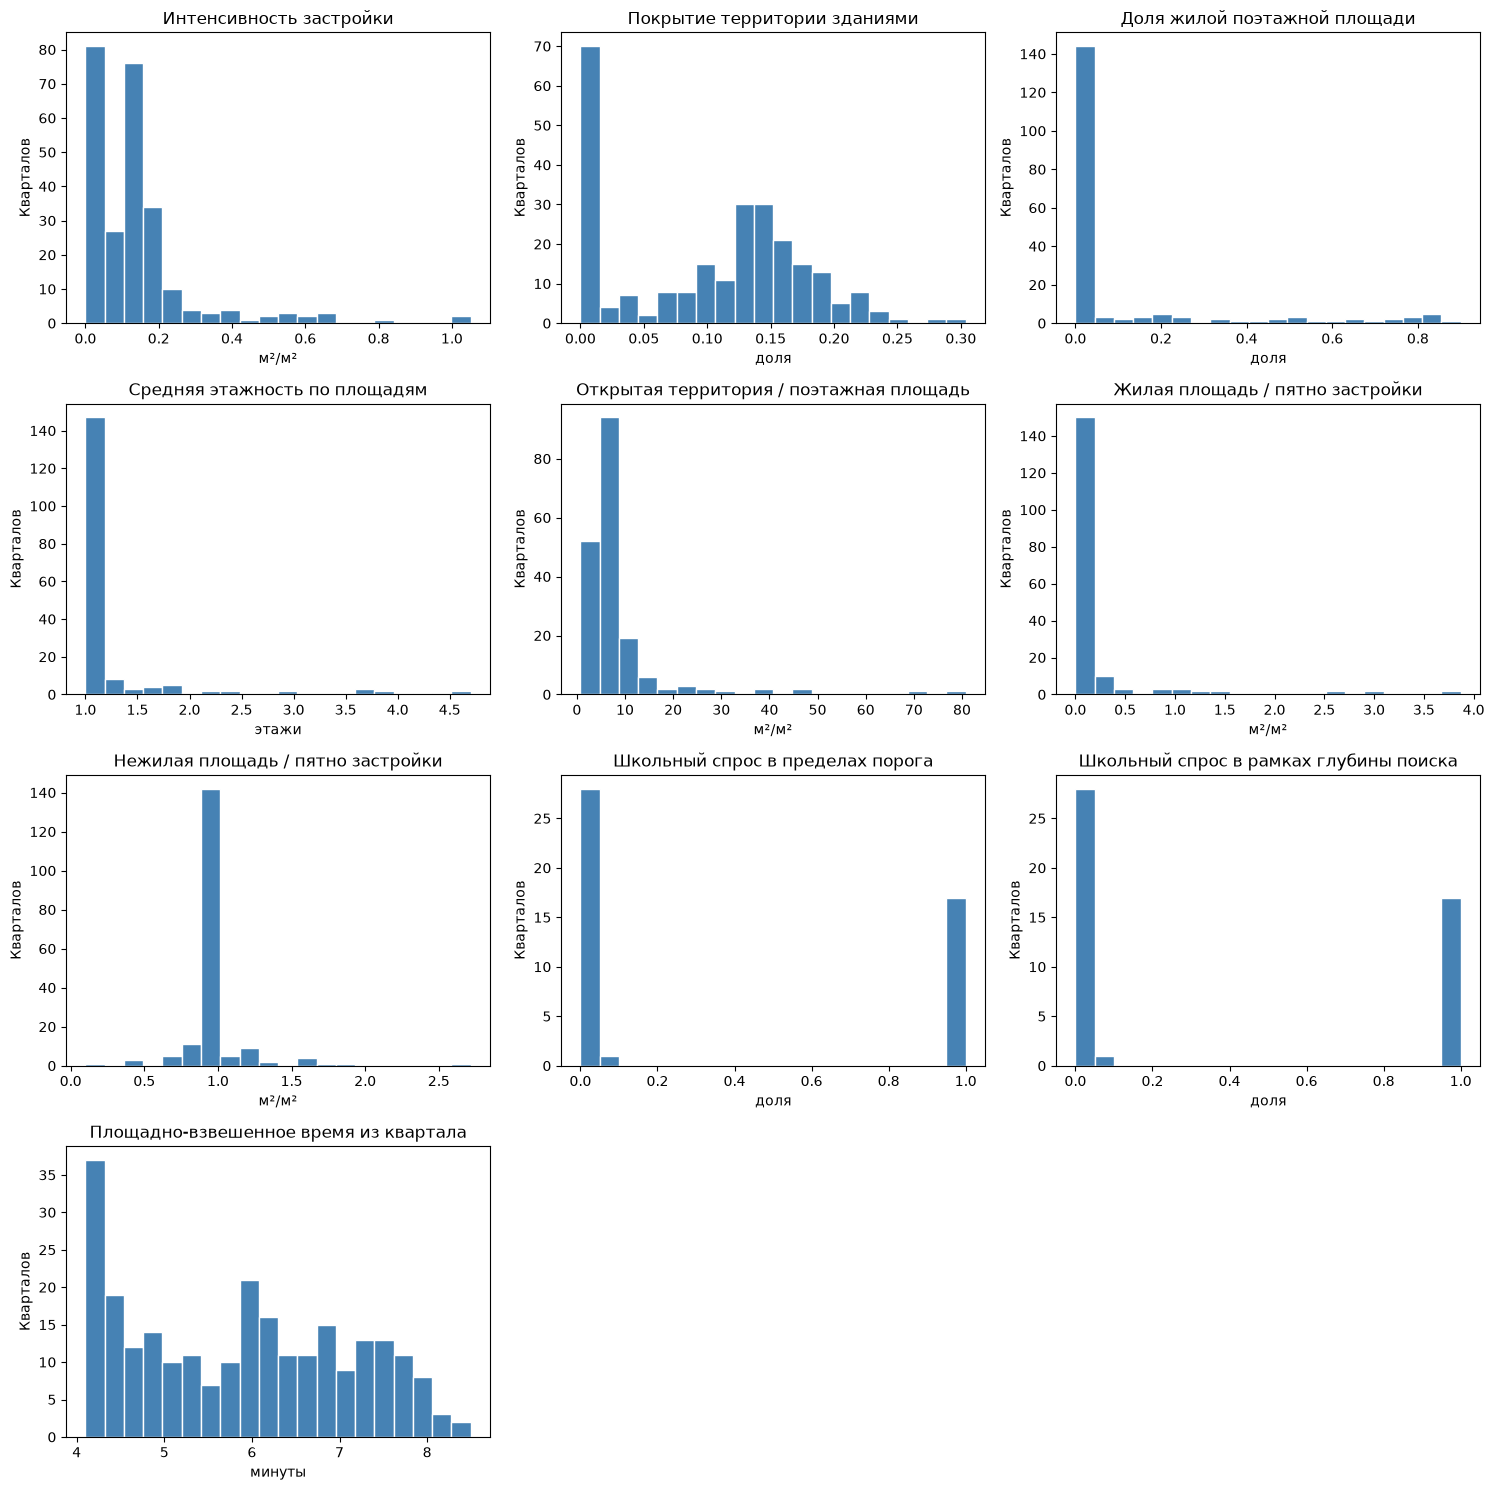

,blocks
spacematrix_morphotype,
low-rise low-density non-residential,164
не определён,68
mid-rise low-density residential,8
low-rise low-density residential,6
low-rise low-density mixed-use,5
mid-rise residential,2


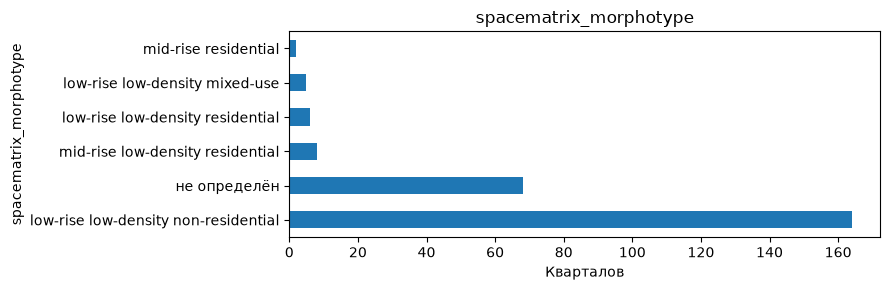

,blocks
strelka_morphotype,
low-rise non-residential,145
не определён,68
low-rise model,35
mid-rise,3
individual residential,2


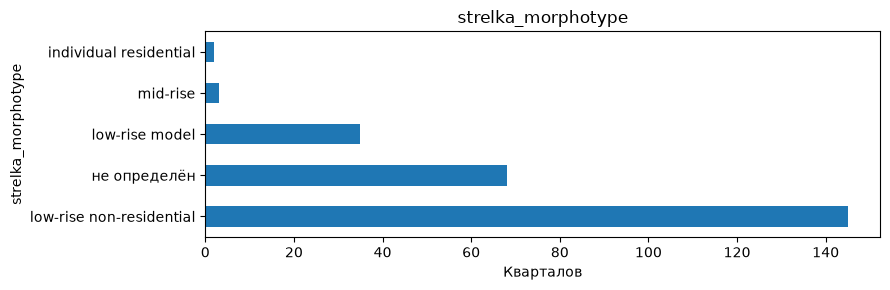

Модельный спрос, мест: 1807.0
Модельная вместимость, мест: 1500.0
Доля удовлетворённого спроса по городу (strong / weak): 0.8301051466519093 0.8301051466519093


,block_id,population,demand,capacity,demand_left,provision_strong
block_id,,,,,,
154,154,586.0,71,0.0,65,0.084507
229,229,425.0,51,0.0,51,0.000000
157,157,246.0,30,0.0,30,0.000000
234,234,148.0,18,0.0,18,0.000000
99,99,146.0,18,0.0,18,0.000000
113,113,104.0,13,0.0,13,0.000000
173,173,96.0,12,0.0,12,0.000000
86,86,86.0,11,0.0,11,0.000000
171,171,71.0,9,0.0,9,0.000000


In [64]:
require_analysis()
NUMERIC_METRICS = DENSITY_COLUMNS + ['provision_strong', 'provision_weak', 'area_accessibility']
statistics = metrics[NUMERIC_METRICS].describe().T
statistics['missing'] = metrics[NUMERIC_METRICS].isna().sum()
statistics.to_csv(DATA / 'results/descriptive_statistics.csv', index_label='metric')
display(statistics)

fig, axes = plt.subplots(4, 3, figsize=(15, 15))
for column, ax in zip(NUMERIC_METRICS, axes.flat):
    values = pd.to_numeric(metrics[column], errors='coerce').replace([np.inf, -np.inf], np.nan).dropna()
    if values.empty:
        ax.text(0.5, 0.5, 'Нет определённых значений', ha='center', transform=ax.transAxes)
    else:
        ax.hist(values, bins=min(20, max(1, len(values))), color='steelblue', edgecolor='white')
    ax.set_title(METRIC_DESCRIPTIONS[column]['label'])
    ax.set_xlabel(METRIC_DESCRIPTIONS[column]['unit'])
    ax.set_ylabel('Кварталов')
for ax in axes.flat[len(NUMERIC_METRICS):]:
    ax.set_visible(False)
fig.tight_layout()
fig.savefig(DATA / 'figures/metric_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

for column in ['spacematrix_morphotype', 'strelka_morphotype']:
    counts = metrics[column].fillna('не определён').value_counts().rename('blocks').to_frame()
    counts.to_csv(DATA / 'results' / f'{column}_counts.csv', index_label='morphotype')
    display(counts)
    ax = counts['blocks'].plot.barh(figsize=(9, max(3, len(counts) * 0.4)), title=column)
    ax.set_xlabel('Кварталов')
    ax.figure.tight_layout()
    ax.figure.savefig(DATA / 'figures' / f'{column}.png', dpi=150, bbox_inches='tight')
    plt.show()

total_demand = float(provision.demand.sum())
CITY_STRONG = float(provision.demand_within.sum() / total_demand) if total_demand > 0 else None
CITY_WEAK = float((provision.demand_within.sum() + provision.demand_without.sum()) / total_demand) if total_demand > 0 else None
print('Модельный спрос, мест:', total_demand)
print('Модельная вместимость, мест:', float(model.capacity.sum()))
print('Доля удовлетворённого спроса по городу (strong / weak):', CITY_STRONG, CITY_WEAK)
display(metrics[['block_id', 'population', 'demand', 'capacity', 'demand_left', 'provision_strong']]
        .sort_values('demand_left', ascending=False).head(15))

In [65]:
require_analysis()
import ipywidgets as widgets


def display_metric(column):
    categorical = METRIC_DESCRIPTIONS[column]['unit'] == 'категория'
    display(Markdown(f'**{METRIC_DESCRIPTIONS[column]["label"]}** · {METRIC_DESCRIPTIONS[column]["unit"]}'))
    display(show_map(metrics, column, categorical=categorical))

selector = widgets.Dropdown(
    options=[(f'{key}: {info["label"]}', key) for key, info in METRIC_DESCRIPTIONS.items()],
    description='Показатель:', layout=widgets.Layout(width='90%'),
)
display(widgets.VBox([selector, widgets.interactive_output(display_metric, {'column': selector})]))

## 12. Проверить качество результатов

Автоматические проверки не заменяют просмотр местности. Таблица ниже выделит вопросы для ручного разбора. Отдельно сравните 3–5 знакомых маршрутов: начало и конец должны соответствовать узлам привязки, способ передвижения — автомобиль. Различия из-за пробок, парковки и времени внутри квартала объясняйте в выводах.

Большая площадь квартала не означает ошибку сама по себе; крупные незастроенные участки могут сильно влиять на площадную доступность. Нулевая обеспеченность не доказывает нехватку школ, пока не проверены полнота OSM, дубли, вместимости и оценка населения.

In [66]:
require_analysis()
unassigned_buildings = read_geojson(DATA / 'prepared/unassigned_buildings.geojson')
unassigned_schools = read_geojson(DATA / 'prepared/unassigned_schools.geojson')
overlap_m2 = float(blocks.area.sum() - blocks.union_all().area)
checks = pd.DataFrame([
    {'check': 'Невалидные кварталы', 'value': int((~blocks.is_valid).sum()), 'needs_review': not blocks.is_valid.all()},
    {'check': 'Суммарные перекрытия кварталов, м²', 'value': overlap_m2, 'needs_review': overlap_m2 > 1.0},
    {'check': 'Непривязанные здания', 'value': len(unassigned_buildings), 'needs_review': len(unassigned_buildings) > 0},
    {'check': 'Непривязанные школы', 'value': len(unassigned_schools), 'needs_review': len(unassigned_schools) > 0},
    {'check': 'Здания с неизвестным назначением', 'value': int(buildings.unknown_use.sum()), 'needs_review': bool(buildings.unknown_use.any())},
    {'check': 'Здания с восстановленной этажностью', 'value': int(buildings.floors_imputed.sum()), 'needs_review': bool(buildings.floors_imputed.any())},
    {'check': 'Школы с модельной вместимостью', 'value': int(schools.capacity_imputed.sum()), 'needs_review': bool(schools.capacity_imputed.any())},
    {'check': 'Длинные привязки к сети', 'value': int(anchors.long_snap.sum()), 'needs_review': bool(anchors.long_snap.any())},
    {'check': 'Недоступные направленные пары', 'value': int(unreachable.sum()), 'needs_review': bool(unreachable.any())},
    {'check': 'Кварталы без Spacematrix', 'value': int(metrics.spacematrix_morphotype.isna().sum()), 'needs_review': metrics.spacematrix_morphotype.notna().sum() == 0},
])
checks.to_csv(DATA / 'results/quality_checks.csv', index=False)
display(checks)

reloaded = read_geojson(DATA / 'results/blocks_metrics.geojson', LOCAL_CRS)
assert reloaded.index.equals(metrics.index)
for column in NUMERIC_METRICS:
    assert np.allclose(pd.to_numeric(reloaded[column]), metrics[column], equal_nan=True)
print('GeoJSON прочитан повторно: идентификаторы и числовые показатели совпали.')
display(metrics[['block_id', 'site_area', 'building_count', 'population']]
        .sort_values('site_area', ascending=False).head(10))

,check,value,needs_review
0,Невалидные кварталы,0.000000e+00,False
1,"Суммарные перекрытия кварталов, м²",1.862645e-09,False
2,Непривязанные здания,0.000000e+00,False
3,Непривязанные школы,0.000000e+00,False
4,Здания с неизвестным назначением,3.320000e+03,True
5,Здания с восстановленной этажностью,3.568000e+03,True
6,Школы с модельной вместимостью,6.000000e+00,True
7,Длинные привязки к сети,1.000000e+00,True
8,Недоступные направленные пары,0.000000e+00,False
9,Кварталы без Spacematrix,6.800000e+01,False


GeoJSON прочитан повторно: идентификаторы и числовые показатели совпали.


,block_id,site_area,building_count,population
block_id,,,,
244,244,1.439081e+06,237.0,260.0
168,168,1.124812e+06,59.0,36.0
90,90,6.863547e+05,24.0,26.0
76,76,6.332858e+05,93.0,41.0
186,186,4.699027e+05,40.0,0.0
205,205,4.430003e+05,63.0,0.0
191,191,2.921682e+05,74.0,0.0
2,2,2.405398e+05,37.0,0.0
23,23,2.366166e+05,24.0,1153.0


### 12.1. Проверить выбранные маршруты

Запишите реальные `block_id` в `ROUTE_CHECK_PAIRS`. Например, `[(3, 12), (12, 3)]`, если такие кварталы у вас есть. В таблице показано время по сети; сравнивайте с тем же способом передвижения и местами привязки. Впишите наблюдения в заключение ниже. Пустой список просто означает, что ручная проверка пока не выполнена.

In [67]:
require_analysis()
ROUTE_CHECK_PAIRS = globals().get('ROUTE_CHECK_PAIRS', [])
rows = []
for source, target in ROUTE_CHECK_PAIRS:
    if source not in blocks.index or target not in blocks.index:
        raise ValueError(f'Неизвестный block_id в паре {(source, target)}')
    rows.append({
        'source': source, 'target': target, 'time_min': float(travel_minutes.loc[source, target]),
        'source_snap_m': float(anchors.loc[source, 'snap_distance_m']),
        'target_snap_m': float(anchors.loc[target, 'snap_distance_m']),
    })
route_checks = pd.DataFrame(rows, columns=['source', 'target', 'time_min', 'source_snap_m', 'target_snap_m'])
route_checks.to_csv(DATA / 'results/route_checks.csv', index=False)
display(route_checks)
if route_checks.empty:
    print('Ручная проверка маршрутов пока не выполнена.')

,source,target,time_min,source_snap_m,target_snap_m


Ручная проверка маршрутов пока не выполнена.


## 13. Выводы и паспорт исследования

В следующей ячейке `OBSERVATIONS` формируется из текущих таблиц: плотность застройки, преобладающий морфотип, автомобильная доступность и школьная модель. Числа обновляются при повторном выполнении ячейки после зависимых расчётов. Дополните список своими наблюдениями. Выводы сохраняются в `summary.json` и попадают в раздел «Выводы» при следующей сборке HTML.

Вопросы для вывода: где застройка плотнее; какие морфотипы преобладают; где модельный школьный спрос не обеспечен; где время выше и почему; насколько результаты зависят от восстановленных данных. Для каждого вывода укажите показатель и конкретные кварталы. Не называйте модельные оценки официальной статистикой.

In [68]:
require_analysis()
school_meta = json.loads((DATA / 'prepared/schools.geojson.meta.json').read_text(encoding='utf-8'))
if SCHOOL_EXCLUDED_OSM_IDS != school_meta['parameters'].get('excluded_osm_ids', {}):
    raise ValueError('Настройки исключения школ изменились. Сначала повторите разделы 4.3–4.4 и 5–12.')

# Выводы по текущим таблицам: значения не зафиксированы на старом школьном сценарии.
gsi_values = density.gsi.replace([np.inf, -np.inf], np.nan).dropna()
fsi_values = density.fsi.replace([np.inf, -np.inf], np.nan).dropna()
strelka_counts = morphotypes.strelka_morphotype.dropna().value_counts()
strelka_names = {
    'low-rise non-residential': 'малоэтажная нежилая застройка',
    'low-rise model': 'малоэтажная модельная застройка',
    'mid-rise': 'среднеэтажная застройка',
    'individual residential': 'индивидуальная жилая застройка',
}
times = accessibility.area_accessibility.replace([np.inf, -np.inf], np.nan).dropna()
strong_text = f'{CITY_STRONG:.2%}' if CITY_STRONG is not None else 'не определена при нулевом спросе'
school_scope_note = (
    ' В выборке есть художественная школа: результат относится к выбранным объектам OSM, '
    'а не только к общеобразовательным школам.'
    if schools.name.fillna('').str.contains('художествен', case=False).any() else ''
)
OBSERVATIONS = [
    (f'В исследовании {len(model)} кварталов. Среднее квартальное покрытие зданиями GSI — '
     f'{gsi_values.mean():.2%}. Это среднее квартальных долей, а не доля зданий во всей площади города.'
     if not gsi_values.empty else 'Для среднего квартального GSI нет определённых значений.')
    + (f' Максимальный FSI — {fsi_values.max():.3f} в квартале №{fsi_values.idxmax()}.'
       if not fsi_values.empty else ''),
    (f'По Strelka среди определённых результатов преобладает морфотип '
     f'«{strelka_names.get(strelka_counts.index[0], strelka_counts.index[0])}»: '
     f'{int(strelka_counts.iloc[0])} из {len(model)} кварталов.'
     if not strelka_counts.empty else 'Определённых морфотипов Strelka нет.')
    + f' Без классификации — {int(morphotypes.strelka_morphotype.isna().sum())} кварталов; '
      'это ограничивает выводы о городской застройке и не означает отсутствие зданий.',
    (f'Конечное площадно-взвешенное время определено для {len(times)} из {len(model)} кварталов. '
     f'Среднее этих значений — {times.mean():.2f} мин; минимум — {times.min():.2f} мин '
     f'в квартале №{times.idxmin()}, максимум — {times.max():.2f} мин в квартале №{times.idxmax()}.'
     if not times.empty else 'Конечных значений площадно-взвешенного времени нет.')
    + ' Время взвешено площадями назначений; пробки, парковка и доступ к узлу графа не учтены.',
    f'В школьной модели {len(schools)} объектов и {model.capacity.sum():.0f} мест при спросе '
    f'{total_demand:.0f} мест. Городская доля спроса, обеспеченного в пределах '
    f'{SCHOOL_TIME_MIN} автомобильных минут, — {strong_text}. '
    f'У {int(schools.capacity_imputed.sum())} из {len(schools)} объектов вместимость восстановлена оценочно; '
    'население также модельное. Результат не является официальной статистикой обеспеченности.'
    + school_scope_note,
    # Добавьте здесь собственные выводы с показателями и ID кварталов.
]

summary = {
    'title': 'Учебное исследование города Лодейное Поле',
    'saved_at_utc': datetime.now(timezone.utc).isoformat(),
    'software': SOFTWARE, 'notebook_revision': NOTEBOOK_REVISION,
    'boundary_query': PLACE_QUERY, 'boundary_sha256': CONFIRMED_BOUNDARY_SHA256,
    'blocks': len(blocks), 'model_population': float(model.population.sum()),
    'schools': len(schools), 'model_school_capacity': float(model.capacity.sum()),
    'school_demand': total_demand, 'city_provision_strong': CITY_STRONG, 'city_provision_weak': CITY_WEAK,
    'graph': GRAPH_PROVENANCE, 'matrix_parameters': travel_parameters,
    'unreachable_pairs': int(unreachable.sum()),
    'assumptions': {
        'default_floors': DEFAULT_FLOORS, 'living_area_coefficient': LIVING_AREA_COEFFICIENT,
        'living_area_per_person_m2': LIVING_AREA_PER_PERSON, 'school_demand_per_1000': SCHOOL_DEMAND_PER_1000,
        'school_accessibility_min': SCHOOL_TIME_MIN, 'provision_max_depth': PROVISION_MAX_DEPTH,
        'provision_self_supply': True, 'spacematrix_n_clusters': SPACEMATRIX_N_CLUSTERS,
        'random_state': RANDOM_STATE, 'school_capacity_missing': 'minimum_typical_from_blocksnet_config',
        'school_excluded_osm_ids': SCHOOL_EXCLUDED_OSM_IDS,
        'accessibility_weights': 'destination_block_site_area', 'connector_time': 'excluded',
    },
    'quality_checks_needing_review': checks.loc[checks.needs_review, 'check'].tolist(),
    'manual_route_pairs_checked': len(route_checks),
    'observations': OBSERVATIONS,
    'sources': {
        'osm': 'https://www.openstreetmap.org/copyright',
        'pipeline': 'https://github.com/aimclub/blocksnet/blob/v1.0.0.a9/examples/pipeline.ipynb',
    },
}
write_json(DATA / 'results/summary.json', summary)
# Контрольные суммы всех файлов данных и таблиц: для сверки на следующем этапе.
write_manifest()
display(Markdown('### Ваши выводы\n' + ('\n'.join(f'- {text}' for text in OBSERVATIONS)
                                             if OBSERVATIONS else 'Выводы ещё не заполнены.')))
print('Паспорт исследования:', DATA / 'results/summary.json')

### Ваши выводы
Выводы ещё не заполнены.

Паспорт исследования: /Users/mariak/ai-course/python-package-boilerplate/examples/data/lodeynoye_pole/results/summary.json


## 14. Повторный запуск и следующий этап

### Продолжить работу завтра

1. В Terminal из папки проекта: `source .venv/bin/activate`, затем `python -m jupyter notebook examples/lodeynoye_pole.ipynb`.
2. Выберите ядро **BlocksNet (.venv)**. Через меню **Kernel → Restart Kernel** начните с чистой памяти. Если ядра нет в списке, зарегистрируйте его командой `ipykernel install` из раздела 0.
3. Для чтения сохранённых данных выполните `environment` → `settings` → `storage-functions` → `restore-saved-results` (раздел 0.1). Оставьте `LOCAL_DATA_ONLY = True`, `SHOW_INTERACTIVE_MAPS = False`, оба `FORCE_* = False`.
4. Для обновлённого экспорта без пересчёта показателей выполните только `combine-results` (раздел 11), затем создайте HTML. Старый паспорт при этом описывает прежний расчёт.
5. Для исправления школьного сценария выполните `analysis-imports`, затем `school-scenario` и остальные ячейки разделов 4.3–4.4, 5–6, 9–13. Точный список ячеек — в [LODEYNOYE_POLE_RERUN.md](LODEYNOYE_POLE_RERUN.md).
6. После изменения входных данных пройдите все зависимые ячейки до паспорта. Кэш проверяет параметры и контрольные суммы файлов; не смешивайте новый список школ со старой моделью.

### Что сохранить и прислать для проверки

- После кварталов: число кварталов, снимок карты, замечания и при необходимости `prepared/blocks.geojson`.
- После полного прохода: `results/blocks_metrics.geojson`, `results/quality_checks.csv`, `results/summary.json`, проверенные маршруты и заполненные выводы.
- Для воспроизводимости сохраните всю папку `examples/data/lodeynoye_pole/`, исходный граф и этот ноутбук.

### Создать одну HTML-страницу

Из корня проекта выполните `.venv/bin/python examples/create_dashboard.py`, затем `open examples/data/lodeynoye_pole/results/dashboard.html`. Скрипт читает локальные результаты, сверяет их и создаёт автономный HTML без запросов к OSM и без запуска ноутбука. Существующий HTML обновится только после вашего запуска этой команды.